# D35. 화자 임베딩: 화자 검증 · 화자 식별 · 위조 음성 탐지

**음성 AI 전문가 과정 | 7주차 M7 서비스 클라이언트 · 실시간 음질 · 대화 설계 · 화자 · 준언어 | 4시간**

## 학습 목표
1. 목소리 한 마디를 숫자 192개(**화자 임베딩**)로 바꾸는 ECAPA-TDNN · WavLM 모델을 쓰고, **코사인 유사도**로 "같은 사람인가"를 점수로 잰다.
2. 본인 · 타인 시도의 점수 분포에서 **FAR(남을 받아들임) · FRR(본인을 거절)** 을 계산하고, **EER**과 서비스에 맞는 **문턱**을 정한다. 등록 문장 수 · 말 길이 · 전화 음질이 EER을 어떻게 바꾸는지 잰다.
3. **화자 검증(1:1, 본인 확인)** 과 **화자 식별(1:N, 가족 중 누구)** 을 만들고, 등록 인원이 늘수록 '모르는 사람'이 들어올 위험이 커지는 것을 확인한다. 목소리 특징을 **동의 · 암호화 · 삭제** 규칙으로 보관한다.
4. **TTS · 녹음 재생 · 목소리 복제(kNN-VC)** 로 우리 검증기를 직접 공격하고, **무작위 문장 읽기 + 위조 음성 탐지기(LFCC)** 를 겹쳐 막는다. 탐지기가 처음 보는 공격에 약하다는 것을 숫자로 확인한다.

## 오늘의 실습 흐름
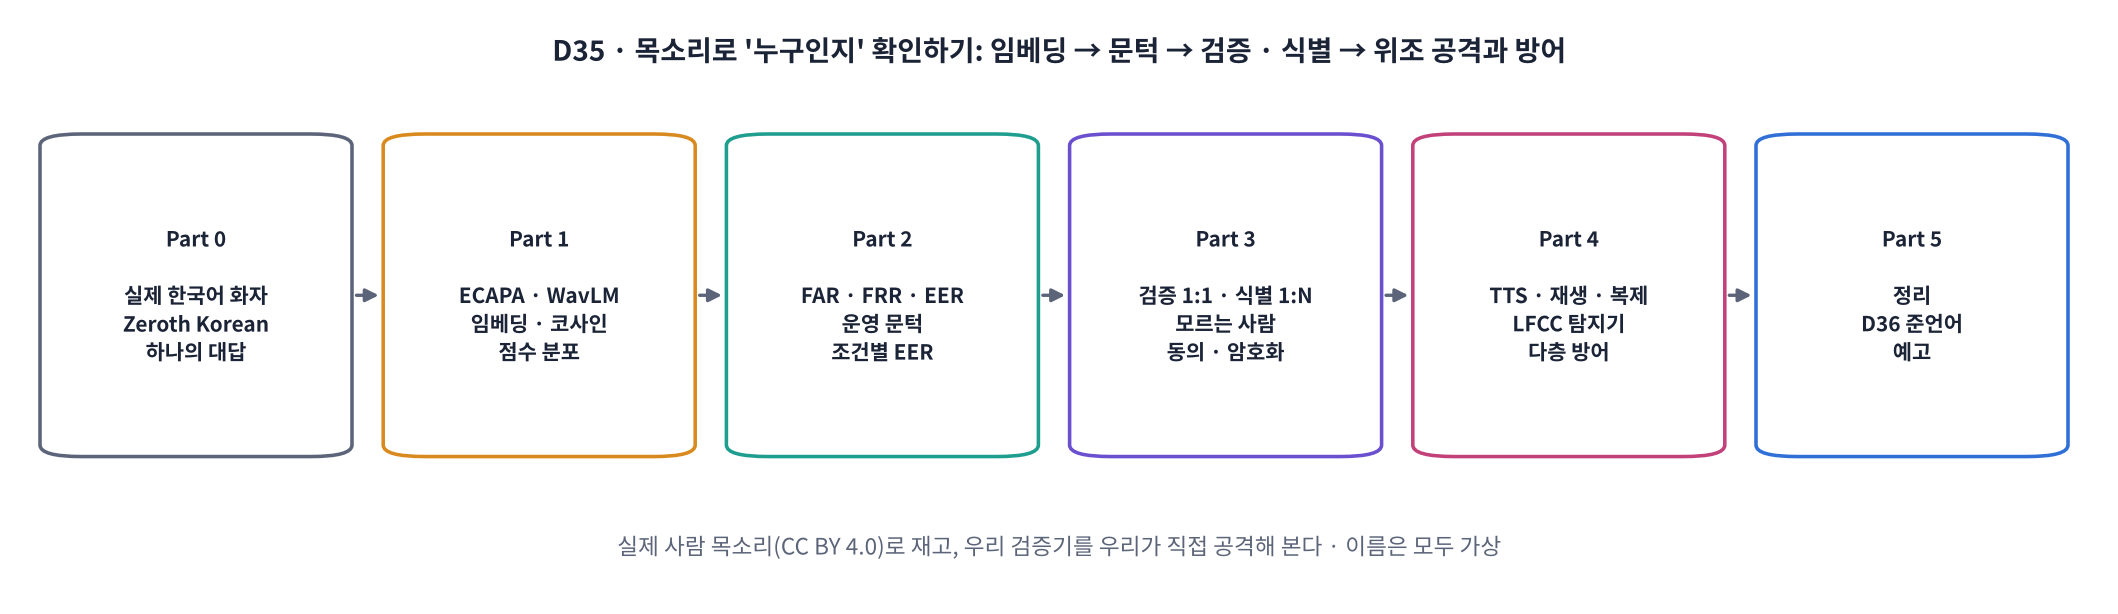

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | 화자 임베딩, 코사인 유사도, 실제 한국어 화자 데이터, 점수 분포 | Part 0 ~ 1 · ✍️ 직접 작성 1 (코사인 함수) | 임베딩 지도(PCA) · 유사도 표 · 본인/타인 점수 분포 |
| 2교시 | FAR · FRR · EER, 문턱 정하기, 등록 수 · 길이 · 전화 음질 · 모델 비교 | Part 2 · ✍️ 직접 작성 2 (FRR 목표 문턱) | EER 곡선 · 운영 문턱 표 · 조건별 EER 표 |
| 3교시 | 화자 검증 · 식별 클래스, '모르는 사람' 거절, 하나의 전화 본인 확인, 생체 정보 보관 | Part 3 · ✍️ 직접 작성 3 (1:N 오수락 확률) | 식별 혼동표 · 등록 인원 vs 오인식 그래프 · 암호화된 템플릿 저장소 |
| 4교시 | TTS · 재생 · 복제 공격, LFCC 위조 탐지기, 겹겹이 막기 | Part 4 ~ 5 · ✍️ 직접 작성 4 (관문 판정) · 워크시트 25문항 | 공격별 통과율 표 · 탐지기 비교표 · 다층 방어 표 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day35/animation.html) | 임베딩 공간(D35-2) · 코사인(D35-3) · FAR/FRR/EER(D35-4) · 문턱 고르기(D35-5) · 등록과 길이(D35-6) · 1:N 식별(D35-7) · 위조 공격과 방어(D35-8). 탭마다 **▶ 시연 보기**를 누르면 자막과 함께 스스로 움직이고, 화살표 · 문턱선은 직접 끌 수 있습니다 |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day35/worksheet.html) | 수업을 모두 마친 뒤 하루 한 장 25문항 (객관식 · OX · 모두 고르기 · 선 잇기 · 순서 · 코드 직접 쓰기 · 계산 · 분류 · 직접 조작), 오답 정리 → 노션 |

## 이 노트북 사용법
- ▶️ 위에서부터 차례로 실행합니다. 오늘은 **실제 사람 목소리**(공개 한국어 낭독 데이터 Zeroth Korean, CC BY 4.0)를 씁니다. 화자 번호만 있고 이름은 없습니다. 수업에서 붙이는 이름(김하늘 등)은 **가상**입니다.
- ⭐ **핵심 코드** 셀은 완성된 코드입니다. 실행한 뒤 `# ⭐` 표시가 붙은 줄을 읽어 보세요. 🔍 **핵심 줄 해설 보기**를 누르면 설명이 펼쳐집니다.
- ✍️ **직접 작성** 셀은 교시마다 하나씩, 모두 네 개입니다. `...` 자리에 코드를 직접 쓰고 실행하면 ✅ 또는 ❌가 나옵니다. 막히면 💡 **힌트 보기**, 다 쓴 뒤에는 🔑 **정답 보기**를 누르세요. 작성하지 않아도 아래 셀은 그대로 실행됩니다.
- ✏️ 표시 셀은 값을 **직접 바꿔** 다시 실행해 보는 셀입니다.
- 🦹 Part 4의 목소리 복제는 **우리 검증기를 시험하는 목적**으로만 씁니다. 만든 소리는 수업 밖으로 내보내지 않습니다(D19 윤리 원칙).

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 소리로 확인 |

> ⚙️ **런타임 → T4 GPU** (임베딩 수천 개 · 목소리 복제에 필요). **키 필요 없음.** 처음 실행 때 모델 · 데이터 내려받기에 3 ~ 5분이 걸립니다.

> 🎬 **애니메이션 D35-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day35/animation.html#flow) — Part 1~5 로드맵과 시간 계획

## Part 0. 준비

> 🛠️ `speechbrain`(ECAPA-TDNN 화자 임베딩, D9에서 씀) · `jiwer`(CER, D10)를 설치합니다. WavLM 화자 임베딩(D19)은 `transformers`, 암호화는 `cryptography`, 분류기는 `scikit-learn`으로 Colab에 이미 있습니다. Whisper · Edge TTS는 D27 ~ D33과 같습니다.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt soundfile speechbrain jiwer
!pip install -q -c colab_constraints.txt uroman edge-tts
print("✅ 설치 완료")

In [ ]:
import os, re, sys, json, time, random, socket, asyncio, warnings, logging
from dataclasses import dataclass
import numpy as np
import pandas as pd
import librosa
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown, Image
import importlib.metadata as md
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)
import io, time, hashlib, tempfile, scipy.fft
from datetime import datetime, timedelta
import soundfile as sf
from scipy import signal
import jiwer
from speechbrain.inference.speaker import EncoderClassifier          # ECAPA-TDNN 화자 임베딩 (D9에서 씀)
from transformers import AutoFeatureExtractor, AutoModelForAudioXVector  # WavLM 화자 임베딩 (D19에서 씀)
from huggingface_hub import HfApi, hf_hub_download                   # 공개 음성 데이터 내려받기
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve
from cryptography.fernet import Fernet                               # 생체 정보 암호화 보관

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000
print(" · ".join(f"{p} {md.version(p)}" for p in ["speechbrain", "transformers", "scikit-learn", "cryptography", "torch"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (CPU로도 가능)")
def verify(cond, what=""):                               # ⭐ 핵심 코드 셀: 결과가 예상과 같은지 스스로 확인
    print(f"✅ 확인: {what}" if cond else f"⚠️ 예상과 다릅니다: {what} → 위 셀을 고쳤다면 원래대로 되돌려 다시 실행하세요.")

def practice(run, want, tol=1e-4):                       # ✍️ 직접 작성 셀 채점: 아직 안 썼거나 오류가 나도 노트북은 계속 실행됨
    try:
        got = run()
    except Exception as e:
        print(f"❌ 실행 중 오류가 났습니다 ({type(e).__name__}: {str(e)[:90]}) · 아래 💡 힌트 보기를 눌러 보세요."); return False
    items = got if isinstance(got, (list, tuple)) else [got]
    if any(x is None or x is Ellipsis for x in items):
        print("✍️ 아직 작성 전입니다. '...' 줄을 지우고 코드를 쓴 뒤 다시 실행하세요. (작성하지 않아도 아래 셀은 그대로 실행됩니다)"); return False
    try:
        ok = bool(np.allclose(np.asarray(got, float), np.asarray(want, float), atol=tol))
    except (TypeError, ValueError):
        ok = list(items) == list(want if isinstance(want, (list, tuple)) else [want])
    show = lambda v: str([round(float(x), 4) if isinstance(x, (int, float, np.floating)) else x for x in (v if isinstance(v, (list, tuple)) else [v])])[:110]
    print("✅ 정답입니다! 🎉" if ok else f"❌ 결과가 다릅니다. 내 결과 {show(got)} · 기대 {show(want)} · 아래 💡 힌트 보기를 눌러 보세요.")
    return ok

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    if len(y): display(Audio(y, rate=sr))
    else: print("   (소리 없음: 위의 경고 · 오류를 확인하세요)")

def silence(sec, sr=SR):
    return np.zeros(int(sec * sr), np.float32)

# D16 정규화 (숫자 → 읽는 말): TTS 바로 앞에서 씀
DIGITS = "영일이삼사오육칠팔구"
def sino(n):
    if n == 0: return "영"
    out = ""
    for big in ["", "만", "억", "조"]:
        chunk, n = n % 10000, n // 10000; s = ""
        for i, unit in enumerate(["", "십", "백", "천"]):
            d, chunk = chunk % 10, chunk // 10
            if d: s = ("" if d == 1 and i > 0 else DIGITS[d]) + unit + s
        if s: out = ("" if s == "일" and big == "만" else s) + big + out
        if n == 0: break
    return out
ONES = ["", "한", "두", "세", "네", "다섯", "여섯", "일곱", "여덟", "아홉"]
TENS = ["", "열", "스물", "서른", "마흔", "쉰", "예순", "일흔", "여든", "아흔"]
def native(n): return sino(n) if not 0 < n < 100 else ("스무" if n == 20 else TENS[n // 10] + ONES[n % 10])
NATIVE_COUNTERS = ["시간", "개", "명", "살", "마리", "권", "잔", "병", "장", "달", "시"]
def normalize_ko(t):
    t = re.sub(r"(\d+)\s*(" + "|".join(NATIVE_COUNTERS) + ")", lambda m: native(int(m.group(1))) + " " + m.group(2), t)
    t = re.sub(r"(\d+)\s*%", lambda m: sino(int(m.group(1))) + " 퍼센트", t)
    t = re.sub(r"\d+", lambda m: sino(int(m.group(0))), t)
    return re.sub(r"\s+", " ", t).strip()
print(normalize_ko("오후 2시에 3명, 주차는 2시간 무료, 할인 10%"))

In [ ]:
# 🔊 모델 준비 (D27 ~ D33과 같음): 받아쓰기 Whisper · 합성 Edge TTS (예비 MMS-TTS) + 하나의 대답 두 가지
from transformers import AutoTokenizer, VitsModel, WhisperProcessor, WhisperForConditionalGeneration
import uroman as ur
tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

import functools, tempfile
VOICE_BOT, VOICE_USER = "ko-KR-SunHiNeural", "ko-KR-InJoonNeural"   # ✏️ Edge 신경망 음성: 비서 · 사용자 대역
TTS_ENGINE = "edge"                                      # 인터넷 · 서비스 문제로 실패하면 자동으로 "mms"(예비)

@functools.lru_cache(maxsize=512)                        # 같은 문장은 다시 요청하지 않음
def _edge_tts(text, voice):
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, voice).save_sync(path)
        return librosa.load(path, sr=SR)[0].astype(np.float32)   # MP3 24 kHz → 16 kHz
    finally:
        os.remove(path)

def _mms_tts(text, seed=0):                              # 예비: MMS-TTS 한국어 VITS (D16)
    set_seed(seed)
    enc = tts_tok(U.romanize_string(text), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        return to_np(tts_model(**enc).waveform[0])

def tts(text, seed=0, voice=None):                       # 글자 → 16 kHz 소리: Edge 신경망 음성, 실패하면 MMS-TTS
    global TTS_ENGINE
    if TTS_ENGINE == "edge":
        try:
            return _edge_tts(text, voice or VOICE_BOT).copy()
        except Exception as e:
            print(f"⚠️ Edge TTS 실패 → MMS-TTS로 전환 ({type(e).__name__}: {str(e)[:80]})"); TTS_ENGINE = "mms"
    return _mms_tts(text, seed)

def user_tts(text, seed=0):                              # 사용자 대역 목소리: 비서와 다른 목소리 (MMS 예비일 때는 3반음 낮춰 구분)
    y = tts(text, seed=seed, voice=VOICE_USER)
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=-3) if TTS_ENGINE == "mms" else y

def stt(y):                                              # 16 kHz 소리 → 글자
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def make_voice(text):                                    # 앞 0.5초 · 뒤 1초 조용함을 붙인 '사용자 말'
    y = np.concatenate([silence(0.5), user_tts(text), silence(1.0)]).astype(np.float32)
    return y / (np.abs(y).max() + 1e-9) * 0.8

# 오늘의 장면: 한빛치과에 전화한 사람이 '목소리로 본인 확인'을 하고 예약을 바꾸려 함
OK_TEXT = "본인 확인되었습니다. 다음 주 수요일 오후 2시 스케일링 예약을 안내해 드릴게요."
NG_TEXT = "목소리로는 확인이 어렵습니다. 본인 확인을 위해 생년월일을 말씀해 주시겠어요?"
play(tts(normalize_ko(OK_TEXT)), SR, "하나 (본인 확인 통과)")
print("받아쓰기 확인:", stt(tts(normalize_ko(OK_TEXT))))

In [ ]:
# 🗂️ 오늘의 목소리: Zeroth Korean 시험 세트 (실제 한국어 화자의 낭독 · CC BY 4.0 · 약 60 MB, 1 ~ 2분)
REPO = "kresnik/zeroth_korean"
MAX_SEC = 8.0                                            # 긴 문장은 앞 8초만 (속도)
MIN_UTT = 12                                             # 문장이 이보다 적은 화자는 뺌

def load_zeroth():
    files = sorted(f for f in HfApi().list_repo_files(REPO, repo_type="dataset") if f.startswith("data/test-"))
    df = pd.concat([pd.read_parquet(hf_hub_download(REPO, f, repo_type="dataset")) for f in files], ignore_index=True)
    wavs = []
    for a in df["audio"]:                                # parquet 안의 소리 파일 바이트를 직접 읽음
        y, sr = sf.read(io.BytesIO(a["bytes"]), dtype="float32")
        if y.ndim > 1: y = y.mean(axis=1)
        if sr != SR: y = librosa.resample(y, orig_sr=sr, target_sr=SR)
        wavs.append(y[:int(MAX_SEC * SR)])
    return pd.DataFrame({"spk": df["speaker_id"].astype(str), "text": df["text"], "wav": wavs})

FALLBACK_VOICES = ["ko-KR-SunHiNeural", "ko-KR-InJoonNeural", "ko-KR-HyunsuMultilingualNeural", "en-US-AvaMultilingualNeural",
                   "en-US-AndrewMultilingualNeural", "en-US-EmmaMultilingualNeural", "en-US-BrianMultilingualNeural",
                   "fr-FR-VivienneMultilingualNeural", "de-DE-SeraphinaMultilingualNeural", "de-DE-FlorianMultilingualNeural"]
FALLBACK_TEXTS = ["다음 주 수요일 오후에 예약하고 싶어요.", "스케일링은 얼마나 걸리나요?", "주차는 몇 시간 무료인가요?", "토요일에도 진료하시나요?",
                  "예약을 목요일로 바꿀 수 있을까요?", "아이도 같이 검진받을 수 있나요?", "잇몸에서 피가 조금 나요.", "점심시간에는 전화가 안 되나요?",
                  "지난번에 받은 치료가 괜찮은지 궁금해요.", "보험 적용이 되는지 알고 싶어요.", "오늘 오후 늦게라도 갈 수 있을까요?", "예약 확인 문자를 못 받았어요."]

def load_fallback():                                     # 예비: 인터넷 문제로 데이터를 못 받으면 Edge TTS 목소리 10개로 (녹음마다 크기 · 잡음을 다르게)
    rng, rows = np.random.default_rng(0), []
    for v in FALLBACK_VOICES:
        for t in FALLBACK_TEXTS:
            try:
                y = _edge_tts(t, v).copy()
            except Exception:
                break
            y = y / (np.abs(y).max() + 1e-9) * rng.uniform(0.3, 0.9) + rng.standard_normal(len(y)).astype(np.float32) * 10 ** (rng.uniform(-60, -40) / 20)
            rows.append({"spk": v.split("-")[2].replace("Neural", ""), "text": t, "wav": y.astype(np.float32)})
    return pd.DataFrame(rows)

try:
    DATA, DATA_NAME = load_zeroth(), "Zeroth Korean 시험 세트 (실제 사람)"
except Exception as e:
    print(f"⚠️ 데이터를 내려받지 못함 → Edge TTS 목소리로 대신 ({type(e).__name__}: {str(e)[:80]})")
    DATA, DATA_NAME = load_fallback(), "Edge TTS 목소리 (예비: 같은 목소리가 늘 똑같아 EER이 실제보다 훨씬 낮게 나옴)"

DATA["sec"] = DATA.wav.map(len) / SR
COUNT = DATA.groupby("spk").agg(문장=("text", "size"), 총길이_분=("sec", lambda s: round(s.sum() / 60, 1)))
SPK_ALL = [s for s in COUNT.sort_values("문장", ascending=False).index if COUNT.loc[s, "문장"] >= MIN_UTT]
DATA = DATA[DATA.spk.isin(SPK_ALL)].reset_index(drop=True)
IDX = {s: DATA.index[DATA.spk == s].tolist() for s in SPK_ALL}       # 화자별 문장 번호
ENROLL_MAX = 5                                           # 화자마다 앞 5문장은 '등록용', 나머지는 '시험용'
TEST_IDX = {s: v[ENROLL_MAX:] for s, v in IDX.items()}
print(f"{DATA_NAME}: 화자 {len(SPK_ALL)}명 · 문장 {len(DATA)}개 · 평균 {DATA.sec.mean():.1f}초")
display(COUNT.loc[SPK_ALL].T)
for s in SPK_ALL[:3]:
    r = DATA.loc[IDX[s][0]]; play(r.wav, SR, f"화자 {s}: {r.text}")

## Part 1. 목소리를 숫자로: 화자 임베딩  ·  1교시

D9에서 회의 녹음을 **누가 말했나**로 나눌 때 ECAPA 임베딩을 잠깐 썼습니다. 오늘은 그 임베딩을 주인공으로, **"이 목소리가 그 사람이 맞나?"** 를 숫자로 답합니다.

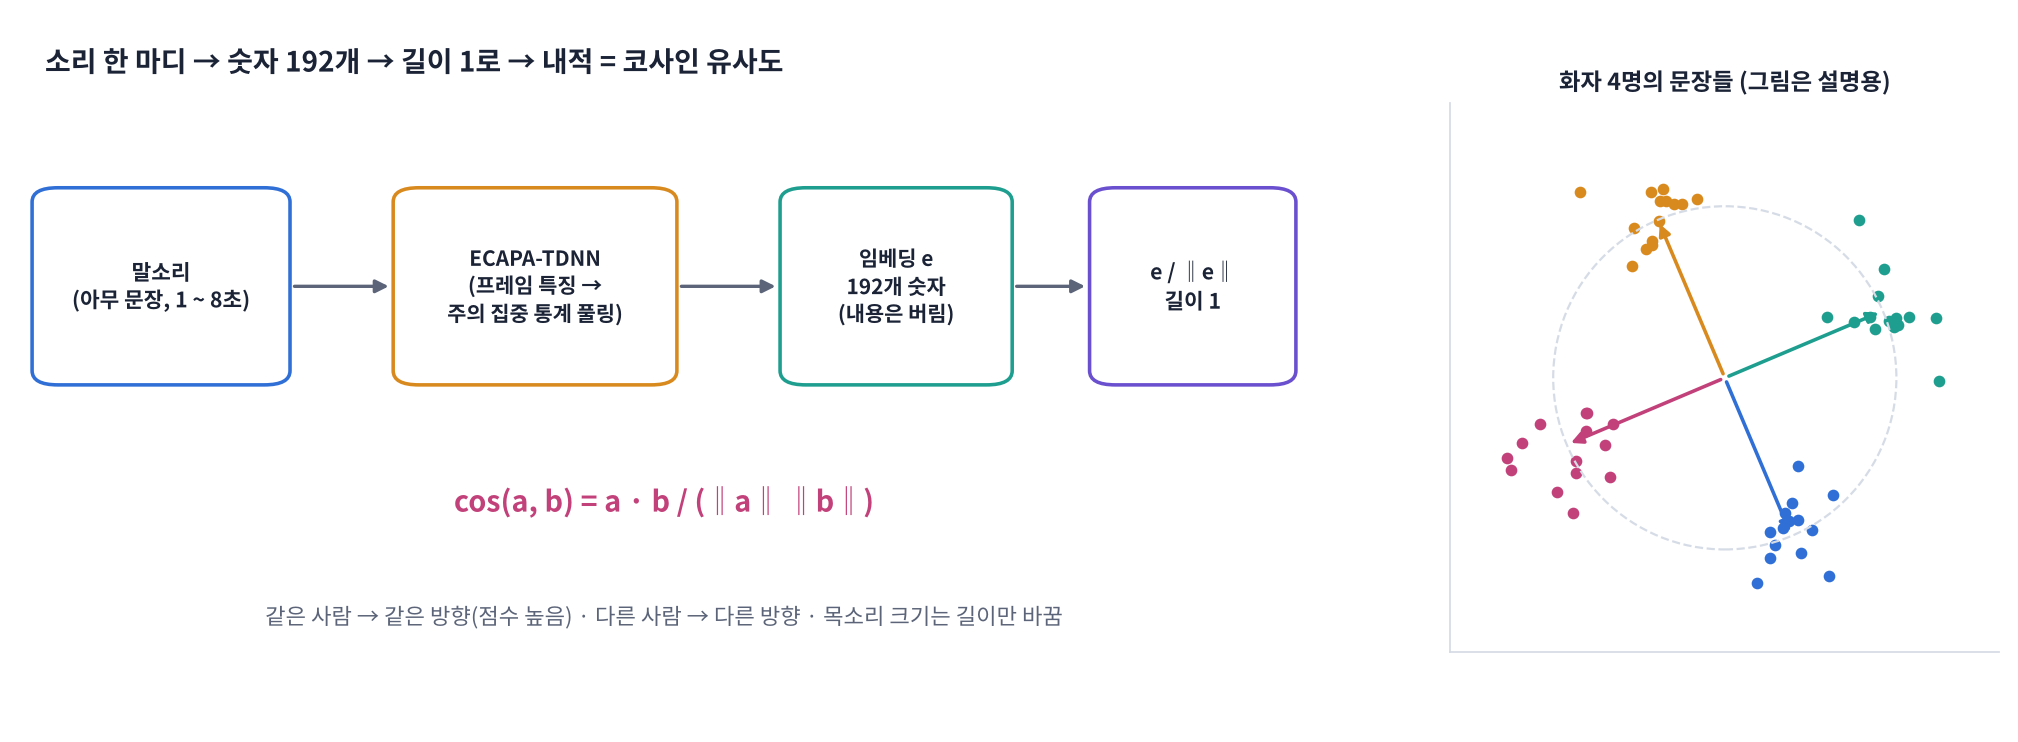

| 이름 | 뜻 | 오늘의 값 |
|---|---|---|
| **화자 임베딩** | 말한 **내용**과 상관없이 **목소리의 특징**만 담은 숫자 묶음(벡터) | ECAPA 192개 · WavLM 512개 |
| **ECAPA-TDNN** | 화자 인식 전용으로 만든 신경망. 수천 명(VoxCeleb)의 목소리로 "같은 사람은 가깝게, 다른 사람은 멀게" 학습 | `speechbrain/spkrec-ecapa-voxceleb` |
| **WavLM-SV** | 큰 자기지도 음성 모델(WavLM)에 화자 검증 머리를 붙인 것 | `microsoft/wavlm-base-plus-sv` |
| **코사인 유사도** | 두 벡터가 **같은 방향**을 보는 정도 (−1 ~ 1) | 같은 사람이면 높고 다른 사람이면 낮음 |

📐 **핵심 식 하나**: `cos(a, b) = a · b / (‖a‖ ‖b‖)` → 먼저 길이를 1로 맞추면(정규화) 그냥 **내적** `a · b`

> 🍎 **비유**: 사람마다 목소리 '지문'이 있습니다. 같은 사람이 다른 문장을 말해도 지문의 **모양(방향)** 은 비슷하고, 크게 말하든 작게 말하든 **크기(길이)** 만 달라집니다. 그래서 길이는 무시하고 방향만 비교합니다.
>
> 💬 **쉽게 말하면**: 목소리를 지도 위의 점 하나로 바꿉니다. 같은 사람의 점끼리는 모여 있고, 다른 사람의 점은 멀리 있습니다.

> 🎬 **애니메이션 D35-2:** [임베딩 공간](https://imguru-mooc.github.io/AI_Voice/day35/animation.html#space) — 같은 사람의 문장은 모이고, 다른 사람은 떨어지는 모습 · 잡음 · 짧은 말이 점을 흔드는 정도

In [ ]:
# 🧠 화자 임베딩 모델 두 가지 (처음 1분 정도)
ecapa = EncoderClassifier.from_hparams(source="speechbrain/spkrec-ecapa-voxceleb", savedir="ecapa", run_opts={"device": DEVICE})
SV_NAME = "microsoft/wavlm-base-plus-sv"
sv_fe = AutoFeatureExtractor.from_pretrained(SV_NAME)
sv = AutoModelForAudioXVector.from_pretrained(SV_NAME).to(DEVICE).eval()
print("ECAPA 파라미터", f"{sum(p.numel() for p in ecapa.mods.parameters()) / 1e6:.1f}M", "· WavLM-SV 파라미터", f"{sum(p.numel() for p in sv.parameters()) / 1e6:.1f}M")

In [ ]:
# ⭐ 핵심 코드: 목소리 → 임베딩 → 길이 1로 맞추기
def embed_ecapa(y):                                      # 16 kHz 소리 → 192개 숫자
    x = torch.tensor(to_np(y))[None].to(DEVICE)          # (1, 샘플 수): 한 번에 여러 개를 넣을 수 있어 앞에 묶음 차원
    with torch.no_grad():
        e = ecapa.encode_batch(x)                        # ⭐ SpeechBrain 화자 모델에서 '묶음을 임베딩으로' 바꾸는 함수
    return e.squeeze().cpu().numpy()                     # (1, 1, 192) → (192,)

def embed_wavlm(y):                                      # 16 kHz 소리 → 512개 숫자 (D19와 같음)
    inp = sv_fe(to_np(y), sampling_rate=SR, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        return sv(**inp).embeddings.squeeze().cpu().numpy()

def l2n(E):                                              # 행마다 길이(L2 노름)를 1로 → 내적 = 코사인 유사도
    E = np.atleast_2d(np.asarray(E, np.float64))
    return E / np.linalg.norm(E, axis=1, keepdims=True)  # ⭐ 행마다 벡터의 길이로 나눔

s0, s1 = SPK_ALL[0], SPK_ALL[1]
a, b, c = (l2n(embed_ecapa(DATA.wav[i]))[0] for i in [IDX[s0][0], IDX[s0][1], IDX[s1][0]])
print("임베딩 모양:", embed_ecapa(DATA.wav[0]).shape, "· 정규화 뒤 길이:", round(float(np.linalg.norm(a)), 4))
print(f"같은 사람 ({s0} 문장 1 vs 문장 2): {a @ b:.3f}")
print(f"다른 사람 ({s0} vs {s1}): {a @ c:.3f}")
verify(embed_ecapa(DATA.wav[0]).shape == (192,) and abs(np.linalg.norm(a) - 1) < 1e-6 and a @ b > a @ c,
       "임베딩이 192개 · 길이 1 · 같은 사람 점수 > 다른 사람 점수")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
e = ecapa.encode_batch(x)
...
return E / np.linalg.norm(E, axis=1, keepdims=True)
```

**해설**: `encode_batch`는 소리 **묶음**(batch, 모양 `(개수, 샘플 수)`)을 받아 `(개수, 1, 192)` 임베딩을 돌려줍니다. 이름에 batch가 있는 이유는 여러 문장을 한 번에 넣어 GPU를 효율적으로 쓰기 위해서입니다(길이가 다르면 `wav_lens`로 실제 길이 비율을 알려 줌). `np.linalg.norm(E, axis=1, keepdims=True)`는 행마다 `√(Σx²)`를 계산해 `(개수, 1)` 모양으로 남기므로 그대로 나눌 수 있습니다. 길이를 1로 맞추면 코사인 유사도가 **그냥 내적**이 되어, 수천 쌍을 행렬 곱 한 번(`E @ T.T`)으로 계산할 수 있습니다.

</details>

In [ ]:
# 📍 모든 문장을 임베딩으로 (T4 약 30초 · CPU는 몇 분)
t0 = time.perf_counter(); E_EC = l2n(np.stack([embed_ecapa(y) for y in DATA.wav])); t_ec = time.perf_counter() - t0
t0 = time.perf_counter(); E_WL = l2n(np.stack([embed_wavlm(y) for y in DATA.wav])); t_wl = time.perf_counter() - t0
print(f"ECAPA {E_EC.shape} {t_ec:.1f}초 · WavLM {E_WL.shape} {t_wl:.1f}초 (문장 하나당 {t_ec / len(DATA) * 1000:.0f} ms · {t_wl / len(DATA) * 1000:.0f} ms)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
P = PCA(2).fit_transform(E_EC)                          # 192차원 → 2차원 그림자 (PCA)
for k, s in enumerate(SPK_ALL):
    ax[0].scatter(*P[IDX[s]].T, s=14, color=plt.cm.tab10(k % 10), label=s)
ax[0].legend(fontsize=7, ncol=2, title="speaker"); ax[0].set_title("ECAPA embeddings projected to 2-D (PCA)", fontsize=10)
pick = sum([IDX[s][:6] for s in SPK_ALL], [])          # 화자마다 6문장씩, 화자 순서로
im = ax[1].imshow(E_EC[pick] @ E_EC[pick].T, cmap="viridis", vmin=0, vmax=1)
ax[1].set_title("cosine similarity (6 sentences per speaker, sorted)", fontsize=10); ax[1].set_xticks([]); ax[1].set_yticks([])
plt.colorbar(im, ax=ax[1], fraction=0.046); plt.tight_layout(); plt.show()

**❓ 생각해 보기**: 오른쪽 그림에서 대각선 위의 **밝은 네모 칸**은 무엇이고, 네모 칸 바깥에도 가끔 밝은 칸이 있는 것은 무엇을 뜻할까요?

<details>
<summary>답 보기</summary>

네모 칸 하나가 **한 사람의 문장 6개끼리** 비교한 점수입니다. 같은 사람끼리는 유사도가 높아 밝습니다. 네모 바깥의 밝은 칸은 **다른 사람인데 비슷하게 들리는 쌍**입니다(성별 · 나이 · 말투 · 녹음 환경이 비슷함). 화자 검증의 오류는 바로 이 칸들에서 생깁니다. 왼쪽 PCA 그림은 192차원을 2차원으로 **그림자만** 본 것이라 겹쳐 보여도 실제로는 떨어져 있을 수 있습니다.

</details>

### 1-1. 본인 시도 vs 타인 시도: 점수 분포

서비스에서는 **등록**(처음에 몇 문장 녹음)과 **검증**(나중에 전화로 한 마디)이 따로 일어납니다.

👣 **한 단계씩**
1. 화자마다 앞 `n_enroll`문장의 임베딩을 **평균** → 길이 1로 = **등록 템플릿**
2. 시험용 문장 하나를 **모든 화자의 템플릿과** 비교
3. 같은 사람 템플릿과의 점수 = **본인 시도(target)**, 다른 사람 템플릿과의 점수 = **타인 시도(non-target, 사칭)**

> 🎬 **애니메이션 D35-3:** [코사인 유사도](https://imguru-mooc.github.io/AI_Voice/day35/animation.html#cosine) — 두 화살표의 각도와 점수, 길이(목소리 크기)는 점수를 바꾸지 않음

In [ ]:
# 🎯 본인 · 타인 시도 점수 만들기
def make_trials(E, n_enroll=3, E_test=None, test_idx=None):
    E_test = E if E_test is None else E_test; test_idx = test_idx or TEST_IDX
    spk = list(test_idx)
    T = {s: l2n(E[IDX[s][:n_enroll]].mean(axis=0))[0] for s in spk}   # 등록 템플릿 = 등록 문장 임베딩의 평균
    tgt, non = [], []
    for s in spk:
        for i in test_idx[s]:
            for c, t in T.items():
                (tgt if c == s else non).append(float(E_test[i] @ t))
    return np.array(tgt), np.array(non)

TGT, NON = make_trials(E_EC)
print(f"본인 시도 {len(TGT)}번 (평균 {TGT.mean():.3f}) · 타인 시도 {len(NON)}번 (평균 {NON.mean():.3f})")
fig, ax = plt.subplots(figsize=(12, 3.2))
bins = np.linspace(min(NON.min(), TGT.min()), 1, 60)
ax.hist(NON, bins, density=True, alpha=0.6, color="#C8553D", label="non-target (impostor)")
ax.hist(TGT, bins, density=True, alpha=0.6, color="#1E9E8F", label="target (same speaker)")
ax.set_xlabel("cosine score"); ax.legend(fontsize=8); ax.set_title("score distributions: the overlap is where errors happen", fontsize=10)
plt.tight_layout(); plt.show()

In [ ]:
# ✍️ 직접 작성 1 (1교시): 코사인 유사도 함수를 처음부터 만들기
# 위에서는 길이를 1로 맞춘 뒤 내적(a @ b)을 썼습니다. 이번에는 '길이를 맞추지 않은' 두 임베딩 u, v를 받아
# 코사인 유사도(숫자 하나)를 돌려주는 함수를 직접 작성하세요. (1 ~ 3줄)
def my_cosine(u, v):
    ...                                                  # ← 이 줄을 지우고 작성하세요

ru, rv, rw = (embed_ecapa(DATA.wav[i]) for i in [IDX[s0][0], IDX[s0][1], IDX[s1][0]])   # 정규화 전 임베딩: 같은 사람 2개 · 다른 사람 1개
unit = lambda x: l2n(x)[0]                               # 채점용 기준값 (위에서 쓴 방법)
if practice(lambda: [my_cosine(ru, rv), my_cosine(ru, rw), my_cosine(ru, 3 * rv), my_cosine(ru, ru)],
            [unit(ru) @ unit(rv), unit(ru) @ unit(rw), unit(ru) @ unit(rv), 1.0]):
    print(f"같은 사람 {my_cosine(ru, rv):.3f} · 다른 사람 {my_cosine(ru, rw):.3f} · 3배 크게 말해도 {my_cosine(ru, 3 * rv):.3f} (그대로)")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 코사인 유사도의 식은 `u · v / (‖u‖ × ‖v‖)` 입니다. 위(분자)는 두 벡터의 **내적**, 아래(분모)는 두 벡터 **길이의 곱**입니다.
2. 내적은 `u @ v` 또는 `np.dot(u, v)`, 길이는 `np.linalg.norm(u)`로 구합니다.
3. `return` 뒤에 `내적 / (길이 × 길이)`를 그대로 옮겨 쓰면 됩니다. 결과를 `float(...)`로 감싸면 숫자 하나가 됩니다.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def my_cosine(u, v):
    return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))
```

**해설**: 분자 `u @ v`는 두 벡터가 같은 방향일수록 커지고, 분모가 두 벡터의 길이를 나눠 없앱니다. 그래서 `v`를 3배로 키워도(크게 말해도) 분자 · 분모가 함께 3배가 되어 **값이 그대로**입니다. 자기 자신과의 코사인은 1입니다. 위 셀의 `l2n(...)` 뒤 `a @ b`는 같은 계산을 '미리 길이로 나눠 두고 내적만' 하는 방식이라, 수천 쌍을 비교할 때 훨씬 빠릅니다.

</details>

> ⏸️ **1교시 끝.** 🎬 D35-2 · D35-3의 **▶ 시연 보기**를 한 번씩 돌려 보세요. 워크시트는 4교시가 끝난 뒤 한 번에 풉니다.

## Part 2. 문턱 정하기: FAR · FRR · EER  ·  2교시

두 분포가 겹치므로 **어디에 선을 긋든 실수가 생깁니다.** 문턱(threshold)을 정하는 순간 두 종류의 실수가 정해집니다.

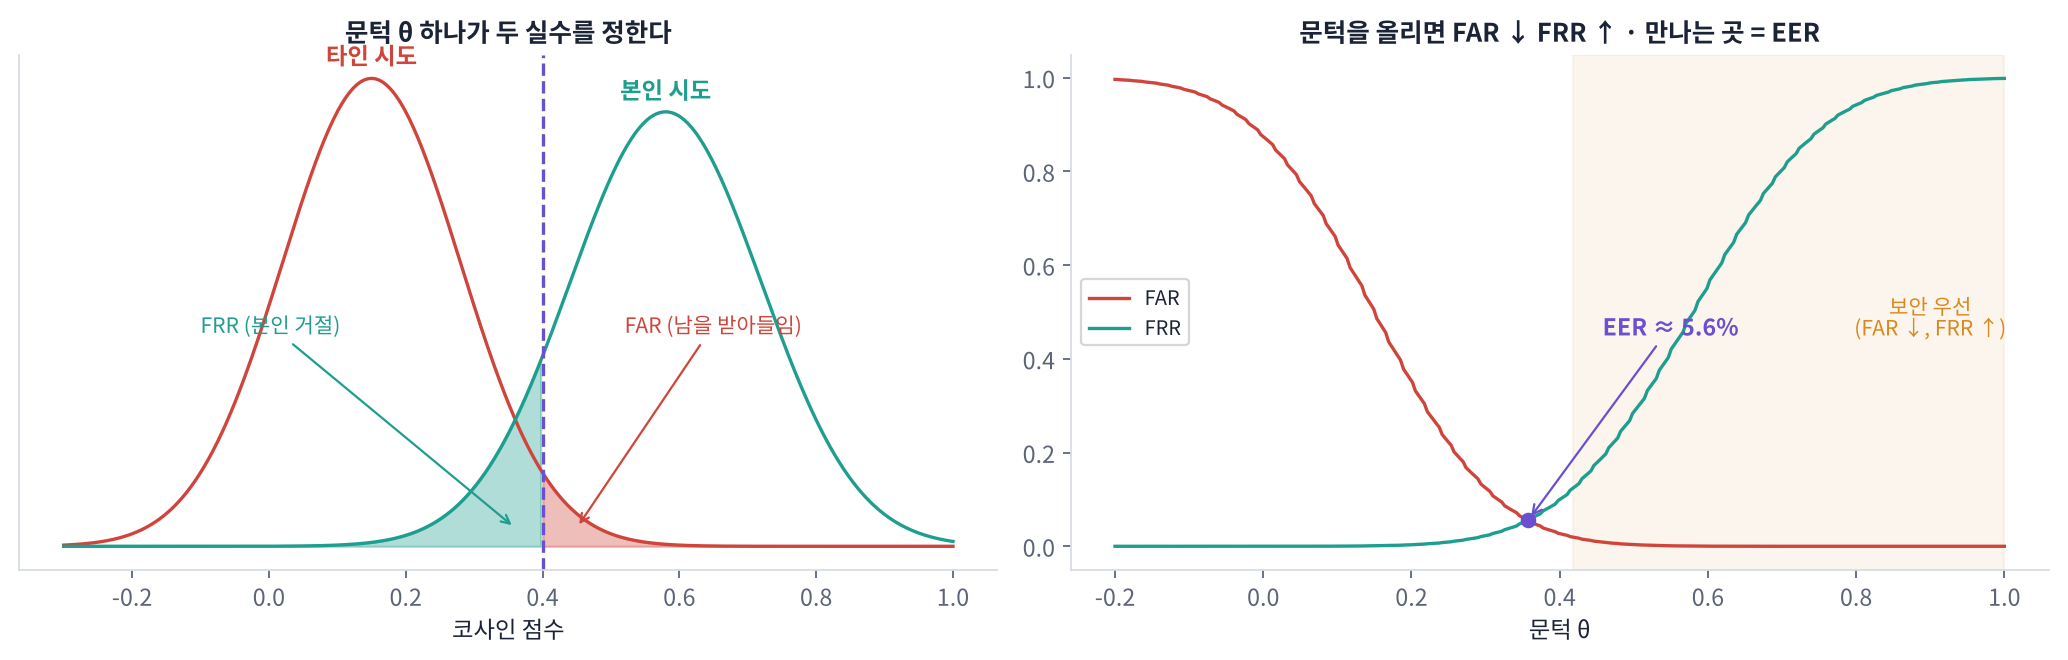

| 실수 | 뜻 | 문턱을 올리면 | 서비스에서의 결과 |
|---|---|---|---|
| **FAR** (False Accept Rate, 오수락률) | 타인 시도 중 **받아들인** 비율 | 줄어듦 | 남이 내 예약 · 진료 기록을 봄 (보안 사고) |
| **FRR** (False Reject Rate, 오거절률) | 본인 시도 중 **거절한** 비율 | 늘어남 | 본인이 "다른 방법으로 확인할게요"를 들음 (불편) |

📐 **핵심 식 하나**: `FAR(θ) = 타인 점수 ≥ θ 인 비율`,  `FRR(θ) = 본인 점수 < θ 인 비율`,  **EER** = 두 곡선이 만나는 곳의 오류율

> 🍎 **비유**: 아파트 출입문 얼굴 인식입니다. 문턱을 낮추면 주민은 잘 들어가지만 비슷하게 생긴 남도 들어오고, 높이면 남은 막지만 주민이 모자를 쓰면 안 열립니다. **EER은 두 실수가 같아지는 지점**으로, 모델끼리 비교하는 하나의 숫자입니다. 실제 문턱은 서비스가 **어느 실수를 더 무서워하는지**로 정합니다.

> 🎬 **애니메이션 D35-4:** [FAR · FRR · EER](https://imguru-mooc.github.io/AI_Voice/day35/animation.html#eer) — 문턱을 움직이며 두 분포의 잘린 넓이 = FAR · FRR, 만나는 점 = EER

In [ ]:
# ⭐ 핵심 코드: FAR · FRR · EER 계산
def far_frr(tgt, non, th):
    far = np.mean(non >= th)                             # ⭐ 남을 본인으로 받아들인 비율 → '타인 점수'에서 셈
    frr = np.mean(tgt < th)                              # 본인을 거절한 비율
    return far, frr

def eer(tgt, non):
    ths = np.sort(np.concatenate([tgt, non]))            # 나올 수 있는 모든 점수를 문턱 후보로
    far, frr = np.array([far_frr(tgt, non, t) for t in ths]).T
    i = np.argmin(np.abs(far - frr))                     # ⭐ FAR과 FRR의 차이가 '가장 작은' 위치
    return (far[i] + frr[i]) / 2, float(ths[i])

EER_EC, TH_EER = eer(TGT, NON)
y_true = np.r_[np.ones(len(TGT)), np.zeros(len(NON))]; fpr, tpr, _ = roc_curve(y_true, np.r_[TGT, NON])
eer_ref = fpr[np.nanargmin(np.abs(1 - tpr - fpr))]      # scikit-learn ROC로 따로 구한 EER (검산용)
print(f"EER {EER_EC:.2%} (문턱 {TH_EER:.3f}) · 검산(scikit-learn) {eer_ref:.2%}")

ths = np.linspace(-0.2, 1, 241); curves = np.array([far_frr(TGT, NON, t) for t in ths])
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(ths, curves[:, 0], color="#C8553D", label="FAR (impostor accepted)"); ax.plot(ths, curves[:, 1], color="#1E9E8F", label="FRR (genuine rejected)")
ax.axvline(TH_EER, color="#6A4FCF", ls="--"); ax.scatter([TH_EER], [EER_EC], color="#6A4FCF", zorder=3, label=f"EER {EER_EC:.1%}")
ax.set_xlabel("threshold"); ax.set_ylabel("error rate"); ax.legend(fontsize=8); ax.set_title("raising the threshold trades FAR for FRR", fontsize=10)
plt.tight_layout(); plt.show()
verify(far_frr(TGT, NON, -2)[0] == 1.0 and far_frr(TGT, NON, 2)[1] == 1.0 and abs(EER_EC - eer_ref) < 0.01,
       "우리 EER이 scikit-learn으로 따로 구한 값과 1% 안에서 같음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
far = np.mean(non >= th)
...
i = np.argmin(np.abs(far - frr))
```

**해설**: FAR은 **타인 시도 중에서** 받아들인 비율이므로 `non` 점수에서 문턱 이상인 것을 셉니다. `np.mean(조건)`은 True를 1로 세어 비율을 줍니다. `tgt >= th`라고 쓰면 그것은 '본인을 받아들인 비율' = `1 − FRR`이라 검산이 틀립니다. EER은 두 곡선이 만나는 곳, 즉 `|FAR − FRR|`이 **가장 작은** 위치(`argmin`)입니다. 점수가 띄엄띄엄 있어 정확히 같아지는 문턱이 없을 수 있어 두 값의 평균을 EER로 씁니다. 실무 도구(scikit-learn `roc_curve`)는 `FPR = FAR`, `1 − TPR = FRR`로 같은 계산을 합니다.

</details>

### 2-1. 서비스에 맞는 문턱: '몇 %의 남을 허용할까'에서 거꾸로

EER 문턱은 비교용입니다. 실제로는 **FAR 목표를 먼저 정하고**(예: 남이 들어올 확률 1%), 그 FAR이 되는 문턱을 타인 점수 분포에서 거꾸로 찾습니다. 타인 점수의 **(1 − 목표 FAR) 분위수**가 그 문턱입니다.

> 🎬 **애니메이션 D35-5:** [문턱 고르기](https://imguru-mooc.github.io/AI_Voice/day35/animation.html#oppoint) — 편의 · 보안 · 은행급 목표를 고르면 문턱과 FRR이 어떻게 바뀌는지, 시도 수가 적으면 FAR 추정이 흔들리는 모습

In [ ]:
# ⭐ 핵심 코드: 목표 FAR에서 문턱 거꾸로 찾기
def th_at_far(non, target_far):
    return float(np.quantile(non, 1 - target_far))       # ⭐ 타인 점수의 (1 − 목표 FAR) 분위수

rows = []
for name, goal in [("편의 우선 (FAR 5%)", 0.05), ("EER 지점", None), ("보안 (FAR 1%)", 0.01), ("은행급 (FAR 0.1%)", 0.001)]:
    th = TH_EER if goal is None else th_at_far(NON, goal); far, frr = far_frr(TGT, NON, th)
    rows.append({"운영 목표": name, "문턱": round(th, 3), "FAR(남을 받아들임)": f"{far:.2%}", "FRR(본인 거절)": f"{frr:.2%}",
                 "받아들인 타인 시도 수": int((NON >= th).sum())})
display(pd.DataFrame(rows))
TH_SEC = th_at_far(NON, 0.01)                            # 오늘 Part 3 · 4에서 쓸 '보안' 문턱
print(f"타인 시도는 {len(NON)}번뿐 → FAR 0.1%는 약 {len(NON) * 0.001:.0f}번의 실수로 정한 문턱 (믿기 어려움, 아래 ❓)")
far1, _ = far_frr(TGT, NON, TH_SEC)
verify(0.005 <= far1 <= 0.012 and TH_SEC > TH_EER, "보안 문턱에서 실제 FAR이 약 1% · EER 문턱보다 높음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
return float(np.quantile(non, 1 - target_far))
```

**해설**: `np.quantile(non, 0.99)`는 타인 점수를 정렬했을 때 99%가 그 아래에 있는 값입니다. 문턱을 거기에 두면 타인 시도의 약 1%만 문턱 이상 → FAR ≈ 1%. 같은 계산을 `np.percentile(non, 99)`로도 할 수 있습니다(0 ~ 100 단위). 목표 FAR이 작을수록 분포의 **꼬리 끝**을 보게 되어 시도 수가 적으면 값이 크게 흔들립니다.

</details>

**❓ 생각해 보기**: 표에서 '은행급(FAR 0.1%)' 문턱은 타인 시도 몇 번의 실수로 정해졌나요? 그 숫자를 믿고 서비스에 '남이 들어올 확률 0.1%'라고 말해도 될까요?

<details>
<summary>답 보기</summary>

타인 시도가 수천 번이면 0.1%는 **몇 번**의 실수뿐이라, 한두 번만 달라져도 FAR이 두 배가 됩니다. 흔히 쓰는 **'30의 법칙'**: 오류율을 믿을 만하게 말하려면 그 오류가 **최소 30번은 관찰**되어야 합니다. FAR 0.1%를 말하려면 타인 시도가 약 **3만 번** 필요합니다. 또 오늘 데이터는 조용한 낭독이라, 실제 전화 · 잡음 · 감기 걸린 목소리에서는 분포가 달라집니다. 그래서 문턱은 **실제 서비스 환경에서 모은 데이터로 다시** 정합니다.

</details>

### 2-2. EER을 바꾸는 것들: 모델 · 등록 수 · 말 길이 · 전화 음질

| 실험 | 바꾸는 것 | 예상 |
|---|---|---|
| 모델 | ECAPA vs WavLM-SV | 화자 전용 학습량 · 구조 차이 |
| 등록 문장 수 | 1 · 3 · 5문장 평균 | 많을수록 템플릿이 안정 |
| 시험 말 길이 | 1 · 2 · 3초로 자르기 | 짧을수록 흔들림 ("네" 한 마디로는 어려움) |
| 전화 음질 | 시험만 8 kHz μ-law (D30) / 등록도 전화로 | 등록과 시험의 **채널이 다르면** 나빠짐 |
| 잡음 | 시험에 SNR 10 dB 잡음 (D33) | 잡음이 목소리 특징을 가림 |

> 🎬 **애니메이션 D35-6:** [등록 수와 말 길이](https://imguru-mooc.github.io/AI_Voice/day35/animation.html#enroll) — 점 구름(한 사람의 문장들)이 등록 · 길이에 따라 퍼지고 좁아지는 모습

In [ ]:
# 🧪 조건별 EER 표 (시험 문장은 화자마다 20개까지, T4 약 1분)
def phone(y):                                            # D30 전화 음질: 8 kHz · 300 ~ 3400 Hz · μ-law 8비트
    y8 = librosa.resample(to_np(y), orig_sr=SR, target_sr=8000)
    y8 = signal.sosfilt(signal.butter(4, [300, 3400], btype="band", fs=8000, output="sos"), y8)
    mu = 255; q = np.sign(y8) * np.log1p(mu * np.abs(np.clip(y8, -1, 1))) / np.log1p(mu); q = np.round(q * 127) / 127
    return librosa.resample((np.sign(q) * ((1 + mu) ** np.abs(q) - 1) / mu).astype(np.float32), orig_sr=8000, target_sr=SR)

def add_noise(y, snr_db=10, seed=0):                     # 분홍빛 잡음을 SNR에 맞춰 (D33)
    rng = np.random.default_rng(seed); n = signal.lfilter([1], [1, -0.9], rng.standard_normal(len(y)))
    return (y + n * np.sqrt(np.mean(y ** 2) / np.mean(n ** 2) / 10 ** (snr_db / 10))).astype(np.float32)

EXP = {s: v[:20] for s, v in TEST_IDX.items()}         # 실험용 시험 문장 (화자마다 20개까지)
def eer_with(test_fn=None, enroll_fn=None, n_enroll=3, E=E_EC, emb=embed_ecapa):
    E_t, E_e = E.copy(), E.copy()
    if test_fn:
        for i in sum(EXP.values(), []): E_t[i] = l2n(emb(test_fn(DATA.wav[i])))[0]
    if enroll_fn:
        for s in SPK_ALL:
            for i in IDX[s][:n_enroll]: E_e[i] = l2n(emb(enroll_fn(DATA.wav[i])))[0]
    return eer(*make_trials(E_e, n_enroll, E_test=E_t, test_idx=EXP))[0]

crop = lambda sec: (lambda y: y[int(0.3 * SR):int((0.3 + sec) * SR)])
t0 = time.perf_counter()
rows = [{"조건": "기준: ECAPA · 등록 3문장 · 전체 길이", "EER": eer_with()},
        {"조건": "모델: WavLM-SV", "EER": eer_with(E=E_WL, emb=embed_wavlm)},
        {"조건": "등록 1문장", "EER": eer_with(n_enroll=1)}, {"조건": "등록 5문장", "EER": eer_with(n_enroll=5)},
        {"조건": "시험 1초", "EER": eer_with(crop(1))}, {"조건": "시험 2초", "EER": eer_with(crop(2))}, {"조건": "시험 3초", "EER": eer_with(crop(3))},
        {"조건": "시험만 전화 음질", "EER": eer_with(phone)}, {"조건": "등록 · 시험 모두 전화 음질", "EER": eer_with(phone, phone)},
        {"조건": "시험에 잡음 SNR 10 dB", "EER": eer_with(add_noise)}]
df_exp = pd.DataFrame(rows); df_exp["EER"] = df_exp["EER"].map(lambda v: f"{v:.2%}")
display(df_exp); print(f"{time.perf_counter() - t0:.0f}초")

**❓ 생각해 보기**: '시험만 전화 음질'보다 '등록 · 시험 모두 전화 음질'의 EER이 더 낮게(좋게) 나오는 경우가 많습니다. 소리 품질은 오히려 나빠졌는데 왜 좋아질까요? 한빛치과가 앱으로 등록하고 전화로 확인한다면 무엇을 해야 할까요?

<details>
<summary>답 보기</summary>

임베딩은 목소리뿐 아니라 **녹음 채널(마이크 · 코덱 · 대역폭)** 의 흔적도 담습니다. 등록과 시험의 채널이 다르면 **같은 사람인데도** 점수가 떨어집니다(채널 불일치). 둘 다 전화면 채널 흔적이 같아 상쇄됩니다. 대책: ① 전화로 확인할 거면 **등록도 전화로** 받기, ② 채널별 템플릿을 따로 두기, ③ 문턱을 채널별로 다시 정하기, ④ 학습 때 코덱 · 잡음 증강(D39). 실서비스에서는 점수 정규화(S-norm 등)로 화자 · 채널마다 다른 점수 분포를 맞추기도 합니다.

</details>

In [ ]:
# ✍️ 직접 작성 2 (2교시): 이번에는 '본인 거절(FRR) 목표'에서 문턱 찾기
# th_at_far는 "남이 들어올 확률(FAR)"을 먼저 정했습니다. 편의가 중요한 서비스는 거꾸로 "본인이 거절될 확률(FRR)"을 먼저 정합니다.
# 본인 점수 tgt에서, FRR이 target_frr가 되는 문턱을 돌려주는 함수를 직접 작성하세요. (1 ~ 2줄)
def th_at_frr(tgt, target_frr):
    ...                                                  # ← 이 줄을 지우고 작성하세요

frr_of = lambda g: None if th_at_frr(TGT, g) is None else far_frr(TGT, NON, th_at_frr(TGT, g))[1]
if practice(lambda: [frr_of(0.05), frr_of(0.01)], [0.05, 0.01], tol=0.008):
    for g in (0.05, 0.01):
        th = th_at_frr(TGT, g); far, frr = far_frr(TGT, NON, th)
        print(f"FRR 목표 {g:.0%} → 문턱 {th:.3f} · 실제 FRR {frr:.2%} · 그때 FAR(남을 받아들임) {far:.2%}")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. FRR은 `np.mean(tgt < th)`, 곧 **본인 점수 가운데 문턱보다 낮은 비율**입니다. 이 비율이 5%가 되려면 문턱은 본인 점수를 줄 세웠을 때 어디에 있어야 할까요?
2. 아래에서부터 5% 지점입니다. `th_at_far`가 타인 점수의 `1 − 목표` 분위수를 썼다면, 이번에는 본인 점수의 `목표` 분위수입니다.
3. `np.quantile(배열, 0 ~ 1 사이 비율)`을 쓰고 `float(...)`로 감싸 돌려주세요.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def th_at_frr(tgt, target_frr):
    return float(np.quantile(tgt, target_frr))
```

**해설**: 본인 점수의 5% 분위수에 문턱을 두면 본인 시도의 약 5%만 문턱 아래로 떨어집니다(FRR ≈ 5%). `th_at_far`와 **거울처럼 반대**입니다: FAR 목표는 타인 점수의 **위쪽 꼬리**(`1 − 목표`), FRR 목표는 본인 점수의 **아래쪽 꼬리**(`목표`)를 봅니다. 출력의 FAR을 보세요. 본인을 편하게 할수록(FRR 목표를 낮출수록) 문턱이 내려가 남이 들어올 확률이 커집니다. 어느 쪽을 먼저 정할지는 서비스가 정할 문제입니다.

</details>

> ⏸️ **2교시 끝.** 🎬 D35-4의 노란 문턱선을 직접 끌어 보고, D35-5 · D35-6의 **▶ 시연 보기**를 돌려 보세요.

## Part 3. 화자 검증 · 화자 식별 만들기  ·  3교시

같은 임베딩으로 두 가지 서비스를 만듭니다. 질문이 다릅니다.

| | **화자 검증 (verification, 1:1)** | **화자 식별 (identification, 1:N)** |
|---|---|---|
| 질문 | "**김하늘 님이 맞나요?**" (주장한 사람이 있음) | "**등록된 가족 중 누구인가요?**" (주장이 없음) |
| 비교 | 주장한 사람의 템플릿 **하나**와 | 등록된 **모든** 템플릿과 → 가장 비슷한 사람 |
| 거절 | 점수 < 문턱 → "다른 방법으로 확인" | 가장 높은 점수도 < 문턱 → **"모르는 사람"** (열린 집합) |
| 한빛치과 예 | 전화로 예약 변경 전 본인 확인 | 가족 계정에서 "엄마 예약 · 아이 예약"을 목소리로 골라 주기 |

📐 **핵심 식 하나 (식별)**: `누구 = argmax_k cos(e, T_k)`, 단 `max_k cos(e, T_k) < θ` 이면 **모르는 사람**

> 🍎 **비유**: 검증은 **신분증 대조**(이 사진이 이 사람인가), 식별은 **단체 사진에서 찾기**(이 사람이 누구인가)입니다. 단체 사진에 사람이 많을수록 **닮은 사람**을 잘못 고를 확률이 커집니다.

> 🎬 **애니메이션 D35-7:** [1:N 식별](https://imguru-mooc.github.io/AI_Voice/day35/animation.html#ident) — 등록 인원을 늘리면 '모르는 사람'이 누군가로 잘못 받아들여질 확률이 커지는 모습

In [ ]:
# ⭐ 핵심 코드: 화자 등록 · 검증 · 식별 클래스
class VoiceID:
    def __init__(self, embed, threshold):
        self.embed, self.th, self.db = embed, threshold, {}          # db: 이름 → 등록 템플릿 (길이 1)
    def enroll(self, name, clips):                                   # 등록: 몇 문장의 임베딩 평균
        self.db[name] = l2n(np.mean([l2n(self.embed(c))[0] for c in clips], axis=0))[0]
    def verify(self, name, clip):                                    # 1:1 본인 확인
        s = float(l2n(self.embed(clip))[0] @ self.db[name])
        return s >= self.th, s
    def identify(self, clip):                                        # 1:N 누구인가 (+ 모르는 사람 거절)
        e = l2n(self.embed(clip))[0]
        scores = {n: float(e @ t) for n, t in self.db.items()}
        best = max(scores, key=scores.get)                           # ⭐ 점수(값)가 가장 큰 '이름(키)'
        return (best if scores[best] >= self.th else "모르는 사람"), scores

N_FAMILY = min(5, len(SPK_ALL) - 2)
FAMILY = dict(zip(["김하늘", "김바다", "이소라", "김구름", "박노을"][:N_FAMILY], SPK_ALL[:N_FAMILY]))   # 가상의 이름 → 데이터의 화자 번호
STRANGERS = SPK_ALL[N_FAMILY:]                                       # 등록하지 않은 사람들
VID = VoiceID(embed_ecapa, TH_SEC)
for name, s in FAMILY.items():
    VID.enroll(name, [DATA.wav[i] for i in IDX[s][:3]])
print("등록:", {n: s for n, s in FAMILY.items()}, "· 문턱(FAR 1%)", round(VID.th, 3), "· 미등록", len(STRANGERS), "명")

rows = []
for who, s in list(FAMILY.items()) + [("모르는 사람", s) for s in STRANGERS]:
    for i in TEST_IDX[s][:8]:
        pred, sc = VID.identify(DATA.wav[i])
        rows.append({"정답": who, "예측": pred, "최고 점수": max(sc.values()), "argmax": max(sc.items(), key=lambda kv: kv[1])[0]})
df_id = pd.DataFrame(rows)
display(pd.crosstab(df_id["정답"], df_id["예측"]))
known = df_id[df_id["정답"] != "모르는 사람"]; unk = df_id[df_id["정답"] == "모르는 사람"]
print(f"등록된 가족을 맞힌 비율 {np.mean(known['정답'] == known['예측']):.0%} · 모르는 사람을 거절한 비율 {np.mean(unk['예측'] == '모르는 사람'):.0%}")
ok = all((r["예측"] == r["argmax"]) or (r["예측"] == "모르는 사람" and r["최고 점수"] < VID.th) for _, r in df_id.iterrows())
verify(ok and len(set(df_id["예측"]) - set(FAMILY) - {"모르는 사람"}) == 0, "식별 결과가 가족 이름 또는 '모르는 사람'으로만 나옴")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
best = max(scores, key=scores.get)
```

**해설**: 사전(dict)에 `max()`를 그냥 쓰면 **키(이름)끼리** 비교해 가나다순으로 가장 뒤의 이름이 나옵니다. `key=scores.get`을 주면 각 키를 `scores.get(키)` = **점수로 바꿔 비교**하고, 이긴 **키**를 돌려줍니다. 같은 일을 `max(scores.items(), key=lambda kv: kv[1])[0]`나 numpy `names[np.argmax(values)]`로도 합니다. 식별에서는 '가장 비슷한 사람'만 고르면 **모르는 사람도 반드시 누군가가 됩니다.** 그래서 최고 점수도 문턱으로 한 번 더 걸러야 합니다(열린 집합 식별).

</details>

In [ ]:
# 📈 등록 인원 N이 늘면 '모르는 사람'이 누군가로 받아들여질 확률은? (임베딩 재사용, 몇 초)
far1 = far_frr(TGT, NON, TH_SEC)[0]; rng = np.random.default_rng(0); rows = []
for N in range(1, len(SPK_ALL)):
    fa = []
    for _ in range(40):
        reg = list(rng.choice(SPK_ALL, N, replace=False)); others = [s for s in SPK_ALL if s not in reg]
        T = l2n(np.stack([E_EC[IDX[s][:3]].mean(axis=0) for s in reg]))
        X = E_EC[sum([TEST_IDX[s] for s in others], [])]
        fa.append(np.mean((X @ T.T).max(axis=1) >= TH_SEC))
    rows.append({"등록 인원 N": N, "측정 (모르는 사람 오수락)": np.mean(fa), "어림 1 − (1 − FAR)^N": 1 - (1 - far1) ** N})
df_n = pd.DataFrame(rows); display(df_n.round(4))
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(df_n["등록 인원 N"], df_n["측정 (모르는 사람 오수락)"], "o-", color="#C8553D", label="measured")
ax.plot(df_n["등록 인원 N"], df_n["어림 1 − (1 − FAR)^N"], "--", color="#6A4FCF", label="1-(1-FAR)^N")
ax.set_xlabel("enrolled speakers N"); ax.set_ylabel("false accept of strangers"); ax.legend(fontsize=8)
ax.set_title(f"1:N open-set: each extra enrolled speaker is one more chance to be wrong (FAR 1:1 = {far1:.1%})", fontsize=10); plt.tight_layout(); plt.show()

**❓ 생각해 보기**: 가족 5명이 아니라 **환자 1만 명**을 등록해 놓고 '전화한 사람이 누구인지' 목소리만으로 찾는다면 어떻게 될까요?

<details>
<summary>답 보기</summary>

1:1 FAR이 1%라도 N = 10,000이면 `1 − 0.99^10000 ≈ 1`, 즉 **모르는 사람도 거의 항상 누군가로** 받아들여지고, 등록된 사람도 닮은 다른 사람으로 잘못 찾힙니다. 그래서 큰 규모에서는 목소리만으로 '누구인지 찾기'를 하지 않고, **전화번호 · 이름으로 후보를 먼저 줄인 뒤 1:1 검증**을 합니다(오늘의 한빛치과 설계). 식별은 가족처럼 **작은 닫힌 집단**에 맞는 기능입니다.

</details>

### 3-1. 하나의 전화 본인 확인

예약 변경처럼 **개인정보가 나가는 행동** 앞에서만 목소리로 확인합니다. 확인이 안 되면 끊지 말고 **다른 방법**(생년월일 · 문자 인증)으로 넘깁니다. 목소리는 **편하게 해 주는 수단**이지 유일한 관문이 아닙니다.

In [ ]:
# 📞 하나: "김하늘 님 본인 확인" (본인이 건 전화 · 남이 건 전화)
def phone_auth(claim, clip):
    ok, s = VID.verify(claim, clip)
    print(f"📞 '{claim}'이라고 함 → 유사도 {s:.3f} (문턱 {VID.th:.3f}) → {'✔ 통과' if ok else '✖ 다른 방법으로 확인'}")
    play(tts(normalize_ko(OK_TEXT if ok else NG_TEXT)), SR, "하나의 대답")
    return ok

me = FAMILY["김하늘"]; other = STRANGERS[0]
play(DATA.wav[TEST_IDX[me][0]], SR, "전화 ① (실제로 김하늘)"); phone_auth("김하늘", DATA.wav[TEST_IDX[me][0]])
play(DATA.wav[TEST_IDX[other][0]], SR, "전화 ② (모르는 사람이 김하늘이라고 함)"); _ = phone_auth("김하늘", DATA.wav[TEST_IDX[other][0]])

### 3-2. 목소리 특징은 '민감정보': 동의 · 암호화 · 삭제

개인정보보호위원회 「생체정보 보호 가이드라인」(2021)은 목소리를 생체정보의 예로 들고, 특정 개인을 알아보려고 만든 **특징정보(오늘의 임베딩 템플릿)** 를 개인정보보호법 시행령 제18조 제3호의 **민감정보**로 봅니다. 민감정보는 다른 개인정보와 **별도로 동의**를 받아야 하고, 안전성 확보 조치 기준은 바이오정보를 **암호화 대상**으로 둡니다. *(법률 자문이 아닙니다. 실제 서비스 전에 최신 법령 · 가이드라인을 확인하세요.)*

| 원칙 | 오늘 코드에서 |
|---|---|
| **별도 동의** · 목적 한정 | 동의 기록(`CONSENT`)에 목적 · 보관 기간 · 대체 수단을 적고, 동의 번호를 템플릿에 붙임 |
| **원본 최소화** | 등록 녹음은 템플릿을 만든 뒤 지움, 템플릿만 남김 |
| **암호화 보관** | 템플릿을 대칭키로 암호화(Fernet). 키는 키 관리 서비스(KMS) · 비밀 저장소에, **코드 · 로그 · 노션에 남기지 않음** |
| **가명 처리** | 저장소의 열쇠는 이름이 아니라 해시값 |
| **삭제(철회)** | 동의 철회 · 기간 만료 → 템플릿 즉시 파기, 이후 검증은 실패해야 함 |

> 💬 **쉽게 말하면**: 비밀번호는 바꿀 수 있지만 목소리는 바꿀 수 없습니다. 그래서 목소리 템플릿은 **비밀번호보다 더 조심해서** 다룹니다.

In [ ]:
# ⭐ 핵심 코드: 템플릿 암호화 보관 · 꺼내기 · 삭제
VAULT_KEY = Fernet.generate_key()                        # 🔐 실서비스: KMS · 비밀 저장소에 보관. 화면 · 로그 · 노션에 출력하지 않음
vault = Fernet(VAULT_KEY)
CONSENT = {"동의 항목": "목소리 특징정보(임베딩) 수집 · 이용", "목적": "전화 예약 변경 시 본인 확인", "보관 기간": "동의일로부터 1년 또는 철회 시까지",
           "원본 녹음": "템플릿 생성 직후 삭제", "대체 수단": "생년월일 + 문자 인증 (목소리 동의를 안 해도 서비스 이용 가능)", "별도 동의": "다른 개인정보 동의와 분리"}

def user_key(name): return hashlib.sha256(("hanbit-salt:" + name).encode()).hexdigest()[:16]   # 실서비스: 비밀 소금(키)으로 HMAC

def seal(name, emb, consent_id):
    blob = vault.encrypt(np.asarray(emb, np.float32).tobytes())      # ⭐ 바이트를 암호화
    now = datetime.now()
    return {"user": user_key(name), "consent_id": consent_id, "model": "ecapa-voxceleb", "created": now.isoformat(timespec="seconds"),
            "expires": (now + timedelta(days=365)).date().isoformat(), "template": blob}

def unseal(rec): return np.frombuffer(vault.decrypt(rec["template"]), np.float32)

STORE = {user_key(n): seal(n, t, f"C-2026-{k:04d}") for k, (n, t) in enumerate(VID.db.items(), 1)}
display(pd.DataFrame([{**{k: v for k, v in r.items() if k != "template"}, "template(앞 32바이트)": r["template"][:32].decode(errors="replace")} for r in STORE.values()]))

def forget(name):                                        # 동의 철회: 저장소 · 메모리 모두에서 지우기
    STORE.pop(user_key(name), None); VID.db.pop(name, None)

raw = np.asarray(VID.db["김하늘"], np.float32).tobytes(); rec = STORE[user_key("김하늘")]
same = np.allclose(unseal(rec), VID.db["김하늘"], atol=1e-6)
forget("김하늘")
print("꺼낸 템플릿이 원래와 같음:", same, "· 삭제 뒤 '김하늘' 등록 여부:", "김하늘" in VID.db, "· 저장소 크기:", len(STORE))
VID.enroll("김하늘", [DATA.wav[i] for i in IDX[FAMILY["김하늘"]][:3]]); STORE[user_key("김하늘")] = seal("김하늘", VID.db["김하늘"], "C-2026-0101")   # 수업용: 다시 등록
verify(isinstance(rec["template"], bytes) and raw not in rec["template"] and same, "저장된 값에 원래 숫자가 보이지 않고, 꺼내면 원래와 같음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
blob = vault.encrypt(np.asarray(emb, np.float32).tobytes())
```

**해설**: `Fernet(key).encrypt(바이트)`는 AES-128-CBC 암호화 + HMAC 위조 검사를 묶은 토큰(바이트)을 돌려주고, `decrypt`로만 되돌릴 수 있습니다. 임베딩(float32 192개 = 768바이트)을 `tobytes()`로 바이트로 바꿔 넣습니다. 같은 템플릿을 두 번 암호화해도 결과가 달라(무작위 IV) 저장소만 보고는 같은 사람인지도 알 수 없습니다. 키를 코드에 적거나 출력하면 암호화한 의미가 없으므로, 실서비스에서는 KMS가 키를 갖고 서버는 꺼낼 때만 잠깐 씁니다. 💡 **임베딩만으로도** 성별 · 나이대를 추정하거나 비슷한 목소리를 만드는 연구가 있어, '숫자뿐이니 괜찮다'가 아닙니다.

</details>

In [ ]:
# ✍️ 직접 작성 3 (3교시): 등록 인원이 n명일 때 '모르는 사람'이 누군가로 받아들여질 확률
# 한 명과 비교할 때 잘못 받아들일 확률이 far입니다. n명과 차례로 비교해 '한 번이라도' 문턱을 넘을 확률을
# 돌려주는 함수를 직접 작성하세요. (비교는 서로 독립이라고 가정 · 1줄)
def p_false_accept(far, n):
    ...                                                  # ← 이 줄을 지우고 작성하세요

if practice(lambda: [p_false_accept(0.01, 1), p_false_accept(0.01, 100), p_false_accept(0.001, 1000)], [0.01, 0.6340, 0.6323], tol=1e-3):
    for n in [1, 5, 100, 10000]:
        print(f"1:1 FAR {far1:.1%} · 등록 {n:>6,}명 → 모르는 사람이 누군가로 받아들여질 확률 {p_false_accept(far1, n):.1%}")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. '한 번이라도 넘을 확률'은 바로 구하기 어렵습니다. 반대쪽인 '**한 번도 안 넘을 확률**'을 먼저 구해 보세요.
2. 한 명과 비교해 안 넘을 확률은 `1 − far`입니다. n명 모두에게 안 넘으려면 이것을 n번 곱합니다: `(1 − far) ** n`.
3. 구하려는 값은 1에서 그것을 뺀 값입니다.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def p_false_accept(far, n):
    return 1 - (1 - far) ** n
```

**해설**: n명 모두에게서 거절될 확률이 `(1 − far)ⁿ`이므로, 한 명에게라도 받아들여질 확률은 `1 − (1 − far)ⁿ`입니다. FAR 1%라도 100명이면 약 63%, 1만 명이면 거의 100%입니다. 위 그래프의 점선이 이 식이고, 실제 측정(실선)은 닮은 사람끼리 점수가 함께 움직여 조금 다르게 나옵니다. 그래서 큰 규모에서는 **번호 · 이름으로 후보를 한 명으로 줄인 뒤 1:1 검증**을 합니다.

</details>

> ⏸️ **3교시 끝.** 🎬 D35-7에서 등록 인원을 바꿔 가며 **100명 전화 걸기**를 눌러 보세요.

## Part 4. 위조 음성 공격과 방어  ·  4교시

목소리로 본인 확인을 한다면 공격자는 **목소리를 흉내** 내려 합니다. 오늘 우리 검증기를 직접 공격해 봅니다.

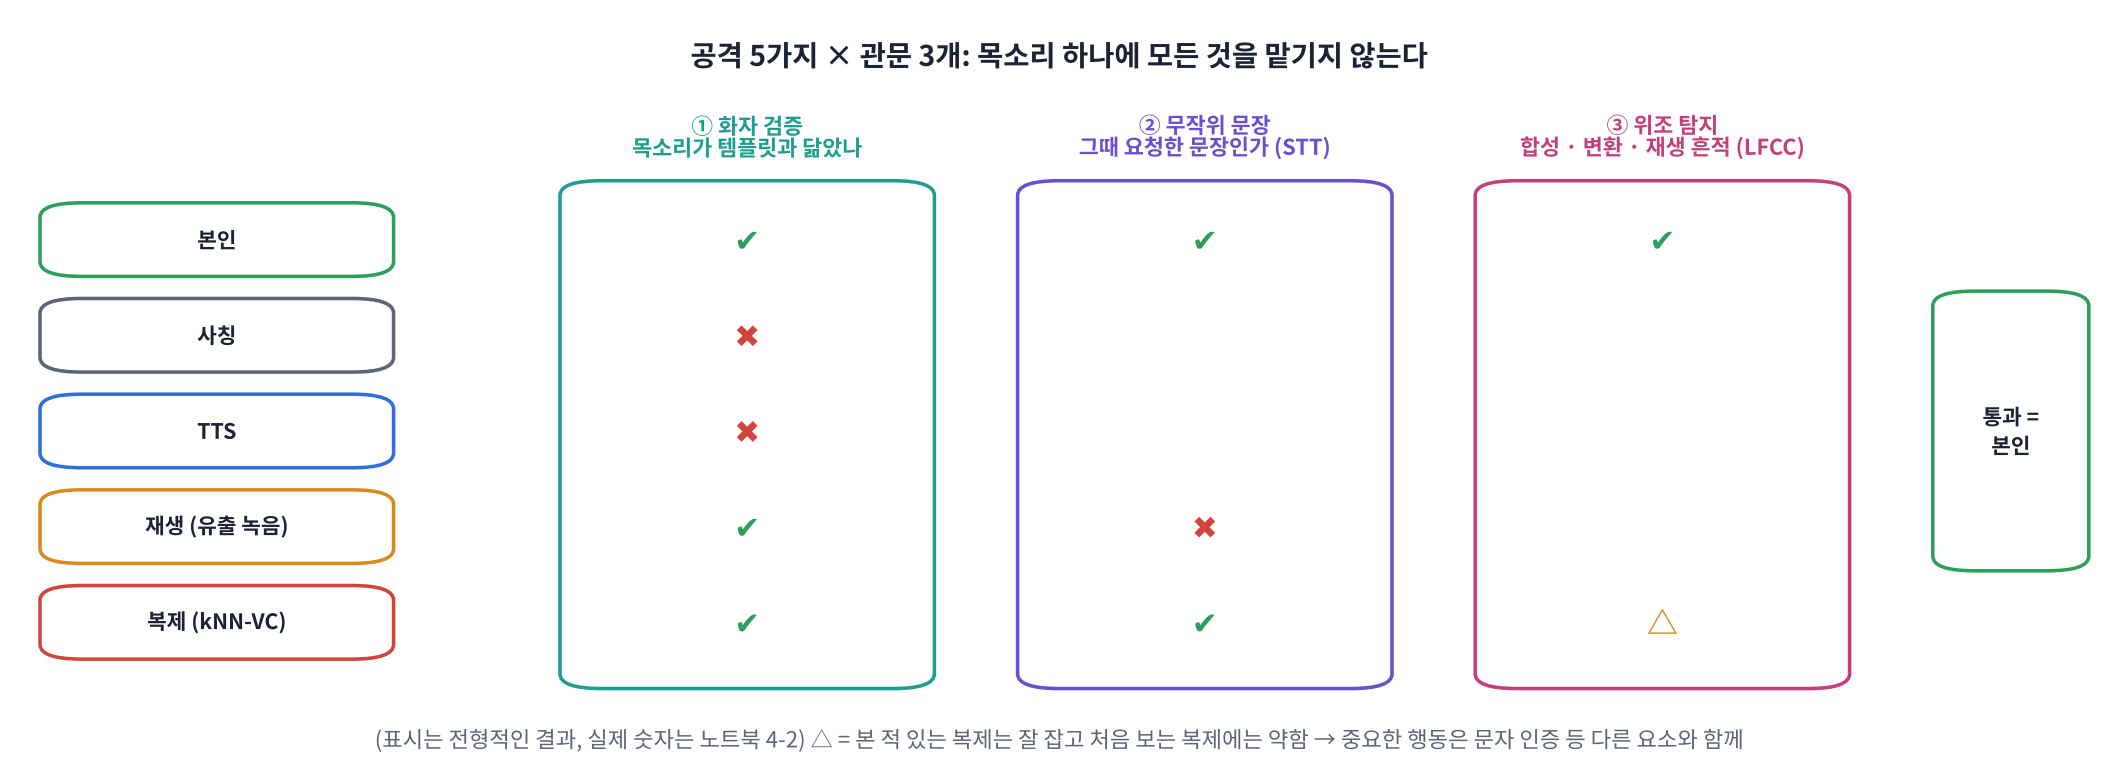

| 공격 | 방법 | 공격자에게 필요한 것 |
|---|---|---|
| **사칭 (zero-effort)** | 그냥 자기 목소리로 "김하늘입니다" | 없음 |
| **TTS** | 아무 TTS 목소리로 읽게 함 | 문장만 |
| **재생 (replay)** | 유출된 본인 녹음(영상 · 음성 메시지)을 전화기에 틀어 줌 | 본인 녹음 몇 개 |
| **복제 (voice conversion · cloning)** | 공격자 말소리를 본인 목소리로 바꿈 (오늘: **kNN-VC**, D19는 Chatterbox) | 본인 녹음 1 ~ 몇 분 |

방어도 겹겹이 둡니다.
1. **화자 검증**: 목소리가 등록 템플릿과 비슷한가 (Part 3)
2. **무작위 문장 읽기 (challenge-response)**: 그때그때 다른 문장을 읽게 하고 받아쓰기로 확인 → **미리 녹음한 소리(재생)** 를 막음
3. **위조 음성 탐지 (anti-spoofing, CM)**: 사람이 낸 소리인가, 합성 · 변환 · 재생된 소리인가

> 🍎 **비유**: 은행 금고입니다. 열쇠(목소리)만으로는 부족해, **그날 바뀌는 비밀번호**(무작위 문장)와 **경비원의 눈**(위조 탐지)을 함께 둡니다. 경비원은 **본 적 있는 수법**은 잘 잡지만 처음 보는 변장에는 속기 쉽습니다.

> 🎬 **애니메이션 D35-8:** [공격과 방어](https://imguru-mooc.github.io/AI_Voice/day35/animation.html#spoof) — 공격 종류를 골라 세 관문(화자 검증 · 무작위 문장 · 위조 탐지)을 통과하는지 보기

In [ ]:
# 🦹 공격 도구 준비: 재생 흉내 · kNN-VC 목소리 변환 (WavLM-Large + HiFi-GAN, 처음 내려받기 1 ~ 2분 · 약 1.3 GB)
def replay(y, seed=0):                                   # 유출 녹음을 스마트폰 스피커로 틀어 전화기 마이크에 들려줌
    rng = np.random.default_rng(seed)
    y = signal.sosfilt(signal.butter(2, [250, 6000], btype="band", fs=SR, output="sos"), to_np(y))   # 작은 스피커: 저음 · 고음 손실
    n = int(0.25 * SR); rir = rng.standard_normal(n) * np.exp(-np.arange(n) / (0.05 * SR)); rir[0] = 8.0   # 짧은 방 울림 (D33)
    y = signal.fftconvolve(y, rir / np.abs(rir).sum() * 4)[:len(y)]
    y = np.tanh(2.0 * y / (np.abs(y).max() + 1e-9)) / 2.0                                          # 스피커의 찌그러짐 (비선형)
    return (y * 0.7 + rng.standard_normal(len(y)) * 10 ** (-55 / 20)).astype(np.float32)

try:
    knn_vc = torch.hub.load("bshall/knn-vc", "knn_vc", prematched=True, trust_repo=True, pretrained=True, device=DEVICE)
except Exception as e:
    knn_vc = None; print(f"⚠️ kNN-VC를 불러오지 못함 → 복제 공격은 건너뜀 ({type(e).__name__}: {str(e)[:80]})")

def _to_files(clips):
    paths = []
    for y in clips:
        fd, p = tempfile.mkstemp(suffix=".wav"); os.close(fd); sf.write(p, to_np(y), SR); paths.append(p)
    return paths

LEAKED = {n: IDX[s][-15:] for n, s in FAMILY.items()}   # 공격자가 구했다고 가정한 '유출 녹음' (약 1 ~ 2분)
_MATCH = {}
def clone_voice(src, target):                            # src(공격자의 말)를 target 목소리로 바꿈. 실패하면 None (복제 공격만 건너뜀)
    global knn_vc
    if knn_vc is None: return None
    try:
        if target not in _MATCH:
            refs = _to_files([DATA.wav[i] for i in LEAKED[target]]); _MATCH[target] = knn_vc.get_matching_set(refs)
            for p in refs: os.remove(p)
        p = _to_files([src])[0]; q = knn_vc.get_features(p); os.remove(p)
        with torch.no_grad():
            return to_np(knn_vc.match(q, _MATCH[target], topk=4))
    except Exception as e:
        print(f"⚠️ kNN-VC 변환 실패 → 복제 공격은 건너뜀 ({type(e).__name__}: {str(e)[:80]})"); knn_vc = None; return None

def says(y, text, max_cer=0.35):                         # 요청한 문장을 읽었나 (받아쓰기 CER, D10)
    norm = lambda s: re.sub(r"[\s.,?!]", "", s)
    return jiwer.cer(norm(text), norm(stt(y)) or "∅") <= max_cer

TARGETS = list(FAMILY)[:3]
print("공격 대상:", TARGETS, "· 유출 녹음", {n: f"{sum(DATA.sec[LEAKED[n]]) / 60:.1f}분" for n in TARGETS}, "· kNN-VC", "준비됨" if knn_vc else "없음")

In [ ]:
# ⚔️ 공격 모음 만들기 + 화자 검증만으로 막아 보기 (T4 약 1분)
FULL = set(DATA.index[DATA.sec < MAX_SEC - 0.1])         # 8초에서 잘리지 않은 문장 (받아쓰기 비교용)
ATTACKS = []
for k, name in enumerate(TARGETS):
    s = FAMILY[name]; gen = [i for i in TEST_IDX[s] if i in FULL][:4]
    for j, i in enumerate(gen):
        ch = DATA.text[i]                                # 하나가 그때 읽어 달라고 한 문장 (= 본인이 실제로 읽은 문장)
        o = STRANGERS[(k + j) % len(STRANGERS)]; i2 = [x for x in TEST_IDX[o] if x in FULL][j % 3]
        src = user_tts(ch)                               # 공격자가 자기 목소리 대신 쓴 TTS (요청 문장을 읽음)
        leak = LEAKED[name][j]
        cand = [("본인", ch, ch, DATA.wav[i]), ("사칭 (다른 사람)", DATA.text[i2], DATA.text[i2], DATA.wav[i2]),
                ("TTS (다른 목소리)", ch, ch, src), ("재생 (유출 녹음)", ch, DATA.text[leak], replay(DATA.wav[leak], seed=j))]
        cl = clone_voice(src, name)
        if cl is not None: cand.append(("복제 (kNN-VC)", ch, ch, cl))
        for kind, challenge, spoken, clip in cand:
            ok, sc = VID.verify(name, clip)
            ATTACKS.append(dict(target=name, kind=kind, challenge=challenge, spoken=spoken, clip=clip, score=sc, speaker_ok=ok))
KINDS = list(dict.fromkeys(a["kind"] for a in ATTACKS))
df_a = pd.DataFrame(ATTACKS)
display(df_a.groupby("kind", sort=False).agg(시도=("score", "size"), 평균_유사도=("score", "mean"), 화자검증_통과율=("speaker_ok", "mean")).round(3))
fig, ax = plt.subplots(figsize=(11, 3))
for k, kind in enumerate(KINDS):
    v = df_a[df_a.kind == kind].score; ax.scatter(v, np.full(len(v), k) + np.random.default_rng(k).uniform(-0.15, 0.15, len(v)), s=30)
ax.axvline(VID.th, color="#C8553D", ls="--"); ax.set_yticks(range(len(KINDS))); ax.set_yticklabels([f"kind {k + 1}" for k in range(len(KINDS))])
ax.set_xlabel("speaker score (red = threshold, FAR 1%)"); ax.set_title("which attacks pass speaker verification alone?", fontsize=10); plt.tight_layout(); plt.show()
print("kind 번호:", {k + 1: kind for k, kind in enumerate(KINDS)})
a = next((x for x in ATTACKS if x["kind"] == "복제 (kNN-VC)"), None)
play(ATTACKS[0]["clip"], SR, f"본인 ({ATTACKS[0]['target']})")
if a is not None: play(a["clip"], SR, f"복제 (kNN-VC → {a['target']})")
play(ATTACKS[3]["clip"], SR, "재생 (유출 녹음)")

**❓ 생각해 보기**: 화자 검증만 있을 때 **어떤 공격이 통과**했나요? '목소리로 본인 확인'을 광고하는 서비스가 이 결과를 보면 무엇을 바꿔야 할까요?

<details>
<summary>답 보기</summary>

보통 **사칭 · TTS는 막히고, 재생 · 복제는 상당히 통과**합니다. 화자 검증은 '목소리가 닮았나'만 보므로, 본인 녹음을 그대로 틀거나 본인 목소리로 바꾼 소리에는 속는 것이 정상입니다. 그래서 ① 재생을 막는 **무작위 문장**, ② 합성 · 변환 흔적을 보는 **위조 탐지**, ③ 중요한 행동(결제 · 개인정보 열람)은 **목소리만으로 허용하지 않고** 문자 인증 등 다른 요소와 묶기가 필요합니다. 실제로 일부 은행이 음성 인증을 복제 음성으로 뚫렸다는 보도가 여러 번 있었습니다.

</details>

### 4-1. 위조 음성 탐지기: LFCC + 로지스틱 회귀

합성 · 변환된 소리에는 **사람 귀에는 잘 안 들리는 흔적**이 남습니다(고음역의 이상한 무늬, 너무 매끈한 배경, 보코더 특유의 결). 위조 탐지에서는 MFCC 대신 주파수를 **고르게 나눈 LFCC**를 자주 씁니다. 멜(MFCC)은 사람 귀처럼 고음을 뭉개는데, 흔적은 오히려 **고음에** 많기 때문입니다.

👣 **한 단계씩**: ① STFT 파워(257개 주파수, 고르게) → ② 로그 → ③ **DCT**로 켑스트럼 20개 → ④ 시간 평균 · 표준편차 · 변화량 → 60개 숫자 → ⑤ 로지스틱 회귀로 "진짜 0 / 위조 1"

🏋️ **학습 데이터**: 진짜 = 화자들의 등록 문장, 위조 = Edge TTS 여러 목소리 + MMS-TTS. **재생 · 복제는 학습에 없음** → "처음 보는 공격"을 얼마나 잡는지가 관심사입니다.

In [ ]:
# ⭐ 핵심 코드: LFCC 특징 (위조 탐지에서 많이 쓰는 특징)
def lfcc(y, n=20):
    S = np.abs(librosa.stft(to_np(y), n_fft=512, hop_length=160)) ** 2   # 257개 주파수 × 시간 (멜이 아니라 고르게)
    keep = S.sum(axis=0) > 1e-4 * S.sum(axis=0).max()                  # 조용한 조각은 빼기
    S = S[:, keep] if keep.sum() >= 5 else S
    C = scipy.fft.dct(np.log(S + 1e-10), type=2, axis=0, norm="ortho")[:n]    # ⭐ 로그 스펙트럼 → 켑스트럼 (MFCC와 같은 변환)
    return np.concatenate([C.mean(axis=1), C.std(axis=1), np.diff(C, axis=1).std(axis=1)])

y0 = DATA.wav[0]; d = lfcc(2 * y0) - lfcc(y0)           # 소리를 2배로 키우면? 로그 파워가 모든 칸에서 log 4만큼 → 0번 계수만 바뀌어야 함
print("LFCC 길이:", lfcc(y0).shape, f"· 2배로 키웠을 때 0번 계수 변화 {d[0]:.2f} (이론 {np.log(4) * np.sqrt(257):.2f}) · 나머지 최대 변화 {np.abs(d[1:20]).max():.4f}")
verify(lfcc(y0).shape == (60,) and abs(d[0] - np.log(4) * np.sqrt(257)) < 1 and np.abs(d[1:20]).max() < 0.5,
       "소리 크기는 0번 계수에만 나타남 (이산 코사인 변환의 성질)")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
C = scipy.fft.dct(np.log(S + 1e-10), type=2, axis=0, norm="ortho")[:n]
```

**해설**: MFCC(D3)와 같은 마지막 단계입니다: 로그 스펙트럼을 **DCT(이산 코사인 변환)** 하면 '스펙트럼의 큰 모양(성도 · 채널)'은 앞 계수에, '잔물결'은 뒤 계수에 모입니다. `type=2, norm="ortho"`이면 0번 계수 = 모든 주파수 로그 파워의 합 / √257 이라, 소리 크기를 바꾸면 **0번만** `log 4 × √257 ≈ 22.2`만큼 움직입니다. 검사 셀은 이 성질로 정답을 확인합니다. MFCC와의 차이는 DCT 앞에 **멜 필터를 쓰지 않는 것** 하나입니다.

</details>

In [ ]:
# 🏋️ 탐지기 학습 + ⭐ 핵심 코드: 위조 점수 (Edge TTS 40문장 만들기 포함, 약 1분)
if DATA_NAME.startswith("Edge"): print("⚠️ 예비 데이터(Edge TTS)를 쓰는 중이라 '진짜 사람'도 TTS입니다. 이 탐지기 결과는 의미가 없습니다.")
REAL_TR = [DATA.wav[i] for s in SPK_ALL for i in IDX[s][:ENROLL_MAX]]          # 진짜 사람 (등록 문장)
TR_VOICES = [v for v in FALLBACK_VOICES if v != VOICE_USER]                    # 공격에 쓴 목소리(VOICE_USER)는 학습에서 뺌
FAKE_TR = []
for k, t in enumerate(DATA.text.drop_duplicates().tolist()[:40]):
    try: FAKE_TR.append(_edge_tts(t[:90], TR_VOICES[k % len(TR_VOICES)]).copy())
    except Exception: pass
FAKE_TR += [_mms_tts(t[:60], seed=k) for k, t in enumerate(DATA.text.drop_duplicates().tolist()[40:52])]
X = np.stack([lfcc(y) for y in REAL_TR + FAKE_TR]); yv = np.r_[np.zeros(len(REAL_TR)), np.ones(len(FAKE_TR))]
DET = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)).fit(X, yv)

def spoof_score(y, det=None):                            # 0에 가까우면 진짜 사람, 1에 가까우면 위조
    return float((det or DET).predict_proba(lfcc(y)[None])[0, 1])   # ⭐ 클래스마다의 확률 → [진짜, 위조] 중 위조 쪽

for a in ATTACKS: a["cm1"] = spoof_score(a["clip"])
df_a = pd.DataFrame(ATTACKS)
print(f"학습: 진짜 {len(REAL_TR)}개 · 위조(TTS) {len(FAKE_TR)}개")
display(df_a.groupby("kind", sort=False).agg(평균_위조점수=("cm1", "mean"), 위조로_잡은_비율=("cm1", lambda v: np.mean(v >= 0.5))).round(3))
tr_fake, tr_real = np.mean([spoof_score(y) for y in FAKE_TR]), np.mean([spoof_score(y) for y in REAL_TR])
verify(all(0 <= a["cm1"] <= 1 for a in ATTACKS) and tr_fake - tr_real > 0.3, "위조 점수가 0 ~ 1 확률이고, 학습한 위조 소리의 점수가 진짜보다 높음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
return float((det or DET).predict_proba(lfcc(y)[None])[0, 1])
```

**해설**: `predict`는 0/1 **결정**만, `predict_proba`는 클래스마다의 **확률** `[[P(진짜), P(위조)]]`을 돌려줍니다. 문턱(오늘은 0.5)을 서비스가 직접 정하려면 확률이 필요합니다(Part 2의 화자 문턱과 같은 이유). `lfcc(y)[None]`은 특징 하나를 `(1, 60)` 표로 만드는 것이고, `[0, 1]`은 첫 번째 줄의 위조 쪽 확률입니다. ⚠️ 오늘 탐지기는 진짜(FLAC 낭독)와 위조(MP3로 받은 TTS)의 **코덱 차이**를 배웠을 가능성도 있습니다. 탐지기가 '무엇을 보고' 판단하는지 늘 의심하세요.

</details>

In [ ]:
# 🔁 복제 소리도 학습에 넣으면? (다른 사람 문장을 첫 번째 대상 목소리로 바꾼 10개, 약 30초)
EXTRA = []
if knn_vc is not None:
    for o in STRANGERS:
        for i in TEST_IDX[o][-2:]: EXTRA.append(clone_voice(DATA.wav[i], TARGETS[0]))
    EXTRA = [y for y in EXTRA if y is not None][:10]
X2 = np.stack([lfcc(y) for y in REAL_TR + FAKE_TR + EXTRA]); y2 = np.r_[np.zeros(len(REAL_TR)), np.ones(len(FAKE_TR) + len(EXTRA))]
DET2 = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)).fit(X2, y2)
for a in ATTACKS: a["cm2"] = spoof_score(a["clip"], DET2)
df_a = pd.DataFrame(ATTACKS)
display(df_a.groupby("kind", sort=False).agg(TTS만_배운_탐지기=("cm1", lambda v: np.mean(v >= 0.5)), 복제도_배운_탐지기=("cm2", lambda v: np.mean(v >= 0.5))).round(3)
        .rename(columns=lambda c: c + " (위조로 잡은 비율)"))
print(f"추가 학습한 복제 {len(EXTRA)}개 (공격 문장 · 공격자 목소리와 다름) · '본인' 줄의 비율 = 진짜 사람을 위조로 잘못 본 비율(오경보)")

**❓ 생각해 보기**: 복제 소리를 학습에 넣으니 복제를 더 잘 잡았습니다. 그럼 **세상의 모든 TTS · 복제 모델**의 소리를 모아 학습하면 해결일까요?

<details>
<summary>답 보기</summary>

매달 새 TTS · 복제 모델이 나오므로 **모든 공격을 미리 모을 수 없습니다.** 탐지기는 본 적 있는 흔적에 강하고 처음 보는 흔적에 약합니다(국제 대회 ASVspoof에서도 '처음 보는 공격'에서 성능이 크게 떨어지는 것이 반복해서 관찰됨). 그래서 ① 탐지기를 **계속 다시 학습**(새 공격 수집 → 레드팀, D49), ② AASIST처럼 원시 파형에서 직접 배우는 더 강한 모델, ③ **무작위 문장 · 다른 인증 요소와 겹쳐 쓰기**, ④ 서비스가 만든 TTS 소리에는 **워터마크**(D19)를 넣어 '우리 TTS'는 바로 알아보기. 탐지기 하나에 모든 것을 맡기지 않는 것이 핵심입니다.

</details>

### 4-2. 겹겹이 막기: 화자 검증 + 무작위 문장 + 위조 탐지

하나는 전화할 때마다 **다른 문장**을 읽어 달라고 하고(오늘은 시험 문장을 그 문장으로 씀), 세 관문을 모두 통과해야 '본인'으로 봅니다.

In [ ]:
# 🛡️ 세 관문을 차례로 (받아쓰기 포함, T4 약 1분)
for a in ATTACKS:
    a["text_ok"] = says(a["clip"], a["challenge"]); a["live_ok"] = a["cm2"] < 0.5
df_a = pd.DataFrame(ATTACKS)
g = df_a.groupby("kind", sort=False)
table = pd.DataFrame({"① 화자 검증만": g.speaker_ok.mean(),
                      "② + 무작위 문장": g.apply(lambda d: np.mean(d.speaker_ok & d.text_ok)),
                      "③ + 위조 탐지 (최종 통과)": g.apply(lambda d: np.mean(d.speaker_ok & d.text_ok & d.live_ok))}).round(3)
display(table)
print("'본인' 줄 = 본인이 통과한 비율(높을수록 좋음) · 나머지 줄 = 공격이 통과한 비율(낮을수록 좋음)")
print("관문마다 걸린 이유 (예시 5개):")
for a in [x for x in ATTACKS if x["kind"] != "본인"][:5]:
    why = [n for n, ok in [("목소리", a["speaker_ok"]), ("문장", a["text_ok"]), ("위조", a["live_ok"])] if not ok] or ["통과!"]
    print(f"  {a['kind']:<14} → {', '.join(why)}")

**❓ 생각해 보기**: 최종 표에서 **본인의 통과율도 떨어졌습니다**(받아쓰기 실수 · 탐지기 오경보). 관문을 늘릴수록 본인이 겪는 불편이 커집니다. 한빛치과라면 어떤 행동에 몇 개의 관문을 둘까요?

<details>
<summary>답 보기</summary>

위험에 맞춰 관문 수를 다르게 둡니다(위험 기반 인증). 예: **진료 시간 문의**는 인증 없음, **예약 확인**은 목소리 + 무작위 문장, **예약 변경 · 진료 기록 · 결제**는 목소리 + 무작위 문장 + 위조 탐지 + **문자 인증**. 어느 관문에서 떨어져도 끊지 말고 대체 수단으로 넘기고(3-1), 떨어진 이유를 로그로 남겨 문턱을 다시 맞춥니다(D43 운영). 본인이 자주 떨어지는 관문은 FRR을 다시 재고, 공격이 통과한 관문은 레드팀 사례로 모아 탐지기를 다시 학습합니다.

</details>

In [ ]:
# ✍️ 직접 작성 4 (4교시): 세 관문 판정 함수 — 어디에서 막혔는지 돌려주기
# x는 전화 한 통의 검사 결과입니다: x["speaker_ok"](목소리가 닮음), x["text_ok"](요청 문장을 읽음), x["live_ok"](위조 흔적 없음).
# ① 목소리 → ② 문장 → ③ 위조 순서로 검사해 '처음 막힌 관문'의 이름("목소리" · "문장" · "위조")을,
# 세 관문을 모두 통과하면 "통과"를 돌려주는 함수를 직접 작성하세요. (4 ~ 6줄)
def gate(x):
    ...                                                  # ← 이 줄을 지우고 작성하세요

case = lambda s, t, l: dict(speaker_ok=s, text_ok=t, live_ok=l)
if practice(lambda: [gate(case(True, True, True)), gate(case(False, True, True)), gate(case(True, False, True)),
                     gate(case(True, True, False)), gate(case(False, False, False)), gate(case(True, False, False))],
            ["통과", "목소리", "문장", "위조", "목소리", "문장"]):
    display(pd.crosstab(pd.Series([x["kind"] for x in ATTACKS], name="전화 종류"), pd.Series([gate(x) for x in ATTACKS], name="결과")))

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 관문을 **순서대로** 검사하고, 막히면 그 자리에서 바로 `return` 하면 됩니다.
2. `if not x["speaker_ok"]: return "목소리"` 처럼 '통과하지 못했으면 이름을 돌려준다'를 세 번 씁니다.
3. 세 `if`를 모두 지나왔다면 마지막 줄에서 `return "통과"`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def gate(x):
    if not x["speaker_ok"]: return "목소리"
    if not x["text_ok"]: return "문장"
    if not x["live_ok"]: return "위조"
    return "통과"
```

**해설**: 앞 관문에서 막히면 뒤 관문은 보지 않습니다(목소리 · 문장이 모두 틀려도 결과는 `"목소리"`). 이렇게 **이유를 남기는 판정**이 있어야 운영에서 '본인이 어느 관문에서 자주 떨어지나(FRR)', '공격이 어느 관문을 통과했나'를 셀 수 있습니다. 출력 표에서 '본인' 줄의 `통과`가 아닌 칸이 본인의 불편이고, 공격 줄의 `통과` 칸이 뚫린 공격입니다. 실제 서비스에서는 막혔을 때 끊지 않고 문자 인증 같은 대체 수단으로 넘깁니다.

</details>

> 📝 **워크시트 25문항**(하루 한 장)을 풀고, **오답 정리**를 복사해 노션에 붙여 넣으세요.

## Part 5. 정리

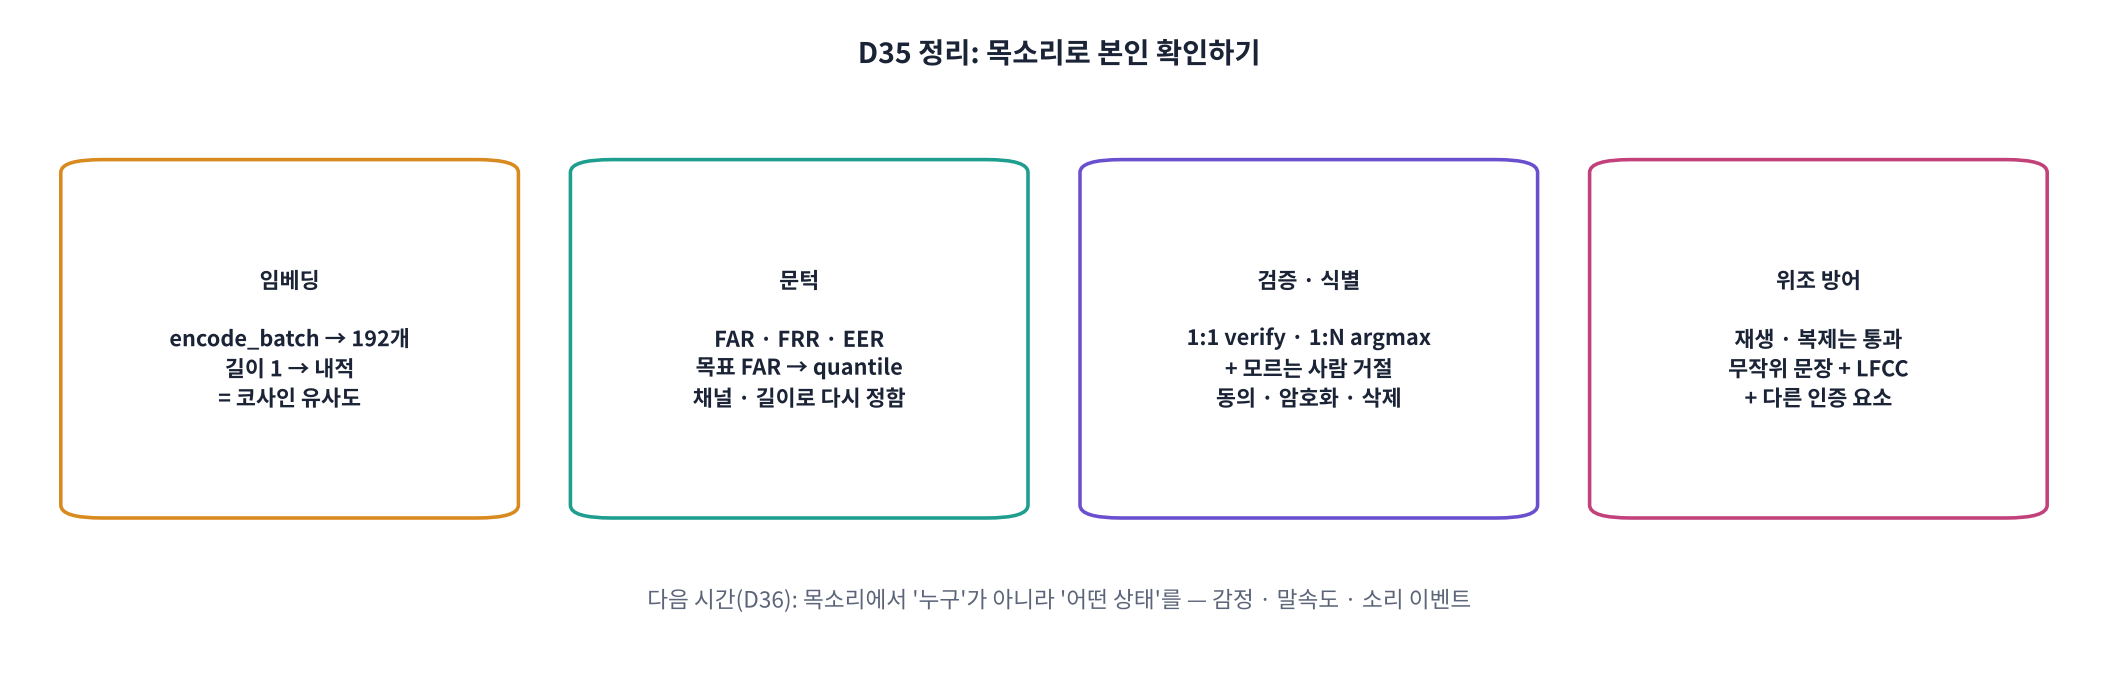

| 오늘 만든 것 | 핵심 | 한 줄 요약 |
|---|---|---|
| 화자 임베딩 | `encode_batch` → 192개, `l2n` → 길이 1 | 내용은 버리고 목소리 특징만 남긴 벡터 |
| 코사인 유사도 | 정규화 뒤 내적 `a · b` | 방향이 같으면 같은 사람 |
| FAR · FRR · EER | `mean(non ≥ θ)` · `mean(tgt < θ)` · `argmin|FAR − FRR|` | 문턱 하나가 두 실수를 맞바꿈 |
| 운영 문턱 | `quantile(non, 1 − 목표 FAR)` | 무서운 실수부터 정하고 거꾸로 찾기 |
| 검증 · 식별 | 1:1 `verify` · 1:N `max(key=get)` + 모르는 사람 | 인원이 늘면 오수락이 늘어남 → 후보를 줄인 뒤 1:1 |
| 생체 정보 보관 | 별도 동의 · `encrypt` · 가명 · 삭제 | 목소리는 바꿀 수 없다 → 비밀번호보다 조심 |
| 위조 탐지 | LFCC `dct` + `predict_proba` | 본 적 있는 공격에 강하고 처음 보는 공격에 약함 |
| 다층 방어 | 화자 + 무작위 문장 + 위조 탐지 (+ 다른 인증) | 목소리 하나에 모든 것을 맡기지 않음 |

### ✅ 오늘의 확인
- [ ] 같은 사람 · 다른 사람의 코사인 점수 분포를 그리고, 겹치는 곳에서 오류가 생긴다는 것을 설명할 수 있다.
- [ ] EER을 직접 계산하고, 서비스 목표(FAR)에서 문턱을 거꾸로 정할 수 있다. 시도 수가 적을 때의 한계를 말할 수 있다.
- [ ] 검증(1:1)과 식별(1:N)의 차이와, 목소리 템플릿 보관 원칙(동의 · 암호화 · 삭제)을 설명할 수 있다.
- [ ] 재생 · 복제 공격이 화자 검증만으로 통과하는 것을 확인하고, 다층 방어를 설계할 수 있다.

### 🔜 D36 예고: 준언어 · 소리 이벤트 분석
- 오늘은 목소리에서 **누구인지**를 봤다면, 내일은 **어떤 상태인지**: 감정 · 말속도 · 피치 · 크기
- 기침 · 비명 · 유리 깨지는 소리 같은 **소리 이벤트** 분류와 CLAP 제로샷
- 감정 추정의 한계와 윤리: 사람을 평가 · 차별하는 데 쓰지 않기

> 🎬 **애니메이션 D35-9:** [정리 퀴즈](https://imguru-mooc.github.io/AI_Voice/day35/animation.html#recap) — 상황별로 문턱 · 등록 · 방어 중 무엇을 고칠지 고르기